In [ ]:
from pathlib import Path
from dataclasses import dataclass, field, asdict
from decimal import Decimal
import gzip, hashlib, json, marshal, re
import numpy as np
import pandas as pd
import scipy
from scipy.ndimage import generate_binary_structure, label, map_coordinates
from scipy.special import erf
import matplotlib.pyplot as plt
try:
    from IPython.display import display, FileLink
except ImportError:
    def display(value):
        print(value.to_string(index=False) if isinstance(value, pd.DataFrame) else value)
    def FileLink(path):
        return str(path)

VERSION = "standalone-coulomb-1.3.0-resolution-aware"
OBJECTIVES = ("global_score", "positive_max_area", "positive_total_area",
              "negative_max_area", "negative_total_area")
EXPORT_COLUMNS = ["rank", "protein", "group", "global_score", "positive_max_area",
                  "negative_max_area", "positive_total_area", "negative_total_area",
                  "angle", "distance_min_A", "distance_mean_A", "distance_max_A",
                  "protein_coverage", "nylon_coverage"]
print("Ready:", VERSION)


Ready: standalone-coulomb-1.3.0-resolution-aware


In [ ]:
MOUNT_DRIVE = True
if MOUNT_DRIVE:
    try:
        from google.colab import drive
    except ImportError:
        print("Local Jupyter: set BASE_DIR to your local data directory.")
    else:
        drive.mount('/content/drive')

BASE_DIR = Path('/content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots')
PROTEIN_PROJECTION_DIR = BASE_DIR / 'planar_projection_v3_single_wall_results_new_dataset_1410'
NYLON_PATH = BASE_DIR / 'Nylon_face_new_size/maps.npz'
OUTPUT_ROOT = BASE_DIR / 'planar_matching_coulomb_fixed_new_dataset_14_10'

PROTEIN_MANIFEST = None

GROUP_OVERRIDES = {}  #{'protein_name': 'Nylonases'}

@dataclass
class Config:
    pixel_size_A: float = 0.25
    gap_A: float = 3.0
    reference_distance_A: float = 3.0
    score_kernel: str = 'coulomb'
    angle_step_deg: float = 1.0
    mirror: bool = True
    interpolation: str = 'nearest'
    connectivity: int = 4
    min_overlap_pixels: int = 20
    min_overlap_area_A2: float = 20.0
    min_overlap_fraction: float = 0.5
    threshold_start: float = 0.05
    threshold_step: float = 0.05
    allow_upsampling: bool = False
    max_canvas_pixels: int = 1_000_000
    max_thresholds: int = 1000

    @property
    def required_overlap_pixels(self):
        return max(self.min_overlap_pixels,
                   int(np.ceil(self.min_overlap_area_A2 / self.pixel_size_A**2 - 1e-12)))

    def validate(self):
        for key in ('pixel_size_A', 'reference_distance_A',
                    'angle_step_deg', 'threshold_start', 'threshold_step'):
            if not np.isfinite(getattr(self, key)) or getattr(self, key) <= 0:
                raise ValueError(f'{key} must be finite and positive.')
        if not np.isfinite(self.gap_A) or self.gap_A < 0:
            raise ValueError('gap_A is a physical plane separation and must be nonnegative.')
        if self.score_kernel not in {'coulomb', 'gaussian'}:
            raise ValueError('score_kernel must be coulomb or gaussian.')
        if self.score_kernel == 'coulomb' and self.reference_distance_A > self.gap_A:
            raise ValueError('Bounded Coulomb descriptor weights require gap_A >= reference_distance_A. '
                             'Use the gaussian kernel for zero-gap surface contact.')
        if self.angle_step_deg >= 360:
            raise ValueError('angle_step_deg must be below 360.')
        if self.interpolation not in {'nearest', 'bilinear'} or self.connectivity not in {4, 8}:
            raise ValueError('Use nearest/bilinear sampling and 4/8 connectivity.')
        if not np.isfinite(self.min_overlap_area_A2) or self.min_overlap_area_A2 < 0:
            raise ValueError('min_overlap_area_A2 must be finite and nonnegative.')
        if not 0 <= self.min_overlap_fraction <= 1:
            raise ValueError('min_overlap_fraction must be between 0 and 1.')
        for key in ('min_overlap_pixels', 'max_canvas_pixels', 'max_thresholds'):
            if not isinstance(getattr(self, key), int) or getattr(self, key) < 1:
                raise ValueError(f'{key} must be a positive integer.')

CONFIG = Config(pixel_size_A=0.25, score_kernel='coulomb',
                gap_A=3.0, reference_distance_A=3.0)
# CONFIG = Config(score_kernel='gaussian', gap_A=0.0, reference_distance_A=3.0)
RESTART_MATCHING = False  #True discard compatible cached rotation profiles
DISPLAY_THRESHOLD = 0.05
DISPLAY_OBJECTIVE = 'positive_total_area'
SHOW_TOP_MAPS = True
TOP_N_MAPS = 50
DOWNLOAD_TXT = False
CONFIG.validate()
OUTPUT_DIR = OUTPUT_ROOT / (f'{CONFIG.score_kernel}_gap{CONFIG.gap_A:g}_ref{CONFIG.reference_distance_A:g}'
                            f'_pixel{CONFIG.pixel_size_A:g}A_areaA2')


REQUIRE_NYLON_SINGLE_WALL = False
REQUIRE_NYLON_FULL_FACE = False


Mounted at /content/drive


## 2. Loading and physical-coordinate transformations

All matching functions are defined inside this notebook. The grid is padded in physical coordinates; array shapes do not determine molecular size. Charge, depth and validity use the same inverse rigid transformation. Nearest-neighbour sampling can reuse a source cell at several target cells; it is raster sampling, rather than one-to-one point matching.


In [ ]:
GROUPS = {
    "Nylonases": "3AXG_NylCa 5XYG_NylCp2 5Y0M_NylCp2_TS NylCk_AF3 nc_NylC_AF3 ph_NylC_AF3 tt_NylC_AF3 TvgC_AF3 9DYS_Nyl50 pam1_AF3".split(),
    "Urethanases": "GatA_AF3 MsmegA_AF3 NfPolyA_AF3 Ooh_AF3 ReU_AF3 TtA_AF3 8S7Z_UMGSP1_AF3 9FVF_UMGSP3_AF3 8WDW_UMGSP2 9FZW_UMGSP2".split(),
}
GROUP_ALIASES = {"8s7z_umgsp1": "8s7z_umgsp1_af3", "9fvf_umgsp3": "9fvf_umgsp3_af3"}


def canonical(name):
    name = re.sub(r"(?:_bfactor)?_mapped_shell$|_shell$", "", str(name), flags=re.I)
    name = re.sub(r"_4rev(?:_aligned)?$", "", name, flags=re.I).lower()
    return GROUP_ALIASES.get(name, name)

def group_of(name):
    key = canonical(name)
    found = [g for g, names in GROUPS.items() if key in {canonical(n) for n in names}]
    if len(found) > 1:
        raise ValueError(f"Conflicting curated labels for {name}.")
    return found[0] if found else "Others"

@dataclass
class Surface:
    name: str
    charge: np.ndarray
    depth_A: np.ndarray
    valid: np.ndarray
    u_A: np.ndarray
    v_A: np.ndarray
    metadata: dict = field(default_factory=dict)
    path: Path | None = None

    @property
    def spacing_A(self):
        return float(np.diff(self.u_A)[0])

def validate_surface(s):
    shape = (len(s.v_A), len(s.u_A))
    if s.charge.shape != shape or s.depth_A.shape != shape or s.valid.shape != shape:
        raise ValueError(f"{s.name}: charge, depth, mask and physical axes disagree.")
    for axis in (s.u_A, s.v_A):
        if len(axis) < 2 or not np.isfinite(axis).all() or np.any(np.diff(axis) <= 0):
            raise ValueError(f"{s.name}: axes must be finite, increasing physical coordinates in Å.")
        if not np.allclose(np.diff(axis), np.diff(axis)[0], rtol=1e-7, atol=1e-9):
            raise ValueError(f"{s.name}: nonuniform grid is unsupported.")
    if not np.isclose(np.diff(s.u_A)[0], np.diff(s.v_A)[0], rtol=1e-7):
        raise ValueError(f"{s.name}: native pixels must be square in physical units.")
    declared_spacing = (s.metadata.get("settings") or {}).get("pixel_size_A")
    if declared_spacing is not None and not np.isclose(float(declared_spacing), s.spacing_A, rtol=1e-7):
        raise ValueError(f"{s.name}: pixel_size_A metadata disagrees with physical axes.")
    if not s.valid.any() or not np.isfinite(s.charge[s.valid]).all() or not np.isfinite(s.depth_A[s.valid]).all():
        raise ValueError(f"{s.name}: missing/nonfinite observed charge or depth.")
    if np.min(s.depth_A[s.valid]) < -1e-7:
        raise ValueError(f"{s.name}: negative depth; expected recession from an outward support plane.")
    s.depth_A[s.valid] = np.maximum(s.depth_A[s.valid], 0.)

def load_surface(path, name=None, require_single_wall=False, require_full_face=False):
    path = Path(path)
    if path.is_dir():
        path = path / "maps.npz"
    with np.load(path, allow_pickle=False) as z:
        needed = {"charge", "depth_A", "valid_mask", "u_A", "v_A", "metadata_json",
                  "plane_origin_A", "plane_normal", "u_axis", "v_axis"}
        if needed - set(z.files):
            raise ValueError(f"{path}: missing {sorted(needed - set(z.files))}; charge PNG/NPY alone is insufficient.")
        meta = json.loads(str(z["metadata_json"].item()))
        facet = meta.get("facet_audit") or {}
        if not isinstance(facet, dict):
            raise ValueError(f"{path}: facet_audit must be a dictionary or null.")
        if meta.get("units", {}).get("depth") != "angstrom" or meta.get("units", {}).get("coordinates") != "angstrom":
            raise ValueError(f"{path}: physical units must explicitly be angstrom.")
        if meta.get("array_convention", "").find("increasing v") < 0:
            raise ValueError(f"{path}: unknown row convention. Convert to increasing-v axes first.")
        if "support plane" not in meta.get("contact_model", "").lower():
            raise ValueError(f"{path}: depth must be recession from an outward support plane, not radius from the centre.")
        frame = np.asarray([z["u_axis"], z["v_axis"], z["plane_normal"]], float)
        if frame.shape != (3, 3) or not np.allclose(frame @ frame.T, np.eye(3), atol=1e-7) or not np.allclose(
                np.cross(frame[0], frame[1]), frame[2], atol=1e-7):
            raise ValueError(f"{path}: the physical projection frame is not orthonormal and right-handed.")
        if require_single_wall:
            valid = z["valid_mask"].astype(bool)
            if "macro_wall_id" not in z.files or np.any(z["macro_wall_id"][valid] != 0):
                raise ValueError(f"{path}: nylon is missing verified single-target-wall provenance.")
            if not facet.get("single_wall_verified", False):
                raise ValueError(f"{path}: nylon single-wall audit failed.")
        if require_full_face and not facet.get("full_operational_target_wall_selected", False):
            raise ValueError(f"{path}: full-face selection is not verified in this export. "
                             "Use a full-face export or set REQUIRE_NYLON_FULL_FACE=False for legacy metadata.")
        s = Surface(name or path.parent.name, z["charge"].astype(float), z["depth_A"].astype(float),
                    z["valid_mask"].astype(bool), z["u_A"].astype(float), z["v_A"].astype(float), meta, path.resolve())
    validate_surface(s)
    return s

def discover_proteins(root, nylon_path=None):
    root = Path(root)
    paths = sorted(root.rglob("maps.npz"))
    excluded = Path(nylon_path).resolve() if nylon_path is not None else None
    selected = []
    for p in paths:
        if p.resolve() == excluded:
            continue
        with np.load(p, allow_pickle=False) as z:
            if "metadata_json" not in z.files:
                raise ValueError(f"Unrecognized projection export: {p}.")
            meta = json.loads(str(z["metadata_json"].item()))

        if meta.get("facet_audit") is not None:
            continue
        selected.append(p)
    paths = selected
    if not paths:
        raise FileNotFoundError(f"No maps.npz under {root}. Set PROTEIN_PROJECTION_DIR to the paired numerical projection outputs.")
    names = [p.parent.name for p in paths]
    if len(set(names)) != len(names):
        raise ValueError("Duplicate projection folder names. Use an explicit unique protein manifest.")
    return dict(zip(names, paths))

def canvas_for_pair(protein, nylon, config):
    """Pad a common physical grid to include ALL rotations; never resize geometry."""
    h = config.pixel_size_A
    if not config.allow_upsampling and h < max(protein.spacing_A, nylon.spacing_A) - 1e-8:
        raise ValueError("The requested grid is finer than an input. Reproject the shell at that resolution, or explicitly allow_upsampling.")
    rp, cp = np.nonzero(protein.valid)
    rn, cn = np.nonzero(nylon.valid)
    radial = np.max(np.hypot(protein.u_A[cp], protein.v_A[rp]))
    extent = max(radial, np.max(np.abs(nylon.u_A[cn])), np.max(np.abs(nylon.v_A[rn])))
    half = int(np.ceil(extent / h)) + 2
    if (2 * half + 1) ** 2 > config.max_canvas_pixels:
        raise ValueError("Physical canvas exceeds max_canvas_pixels. Check units or choose a coarser common physical spacing.")
    axis = np.arange(-half, half + 1, dtype=float) * h
    return axis, np.meshgrid(axis, axis)

def sample_surface(s, U, V, angle_deg=0., mirror=False, offset_A=(0., 0.), interpolation="nearest"):
    """Inverse of target_xy = R(angle) @ diag(-1,1) @ source_xy + offset.

    A single reflection plus reversal of the outward normal is a proper 3D
    180-degree face flip. Depth magnitude is preserved, never negated.
    Bilinear sampling rejects any contribution from a missing source cell.
    """
    theta = np.deg2rad(angle_deg)
    c, t = np.cos(theta), np.sin(theta)
    c = 0. if abs(c) < 1e-12 else c
    t = 0. if abs(t) < 1e-12 else t
    x, y = U - offset_A[0], V - offset_A[1]
    us, vs = c * x + t * y, -t * x + c * y
    if mirror:
        us = -us
    coords = np.array([(vs - s.v_A[0]) / s.spacing_A, (us - s.u_A[0]) / s.spacing_A])
    close = np.isclose(coords, np.rint(coords), rtol=0, atol=1e-10)
    coords[close] = np.rint(coords[close])
    order = 0 if interpolation == "nearest" else 1
    support = map_coordinates(s.valid.astype(float), coords, order=order, mode="constant", cval=0., prefilter=False)
    valid = support >= 1. - 1e-10
    out = []
    for a in (s.charge, s.depth_A):
        sampled = map_coordinates(np.where(s.valid, a, 0.), coords, order=order, mode="constant", cval=0., prefilter=False)
        sampled[~valid] = np.nan
        out.append(sampled)
    return out[0], out[1], valid


In [ ]:
def charge_scale(surface):
    value = float((surface.metadata.get('settings') or {}).get('charge_scale', 1.0))
    if not np.isfinite(value) or value <= 0:
        raise ValueError(f'{surface.name}: invalid charge_scale.')
    return value


def threshold_grid(upper_bound, config):
    start, step = Decimal(str(config.threshold_start)), Decimal(str(config.threshold_step))
    upper = Decimal(str(float(upper_bound)))
    result = [float(start)]
    while Decimal(str(result[-1])) < upper:
        if len(result) >= config.max_thresholds:
            raise ValueError('Too many thresholds: check input charge units or threshold_step.')
        result.append(float(start + len(result) * step))
    return result


def score_upper_bound(protein, nylon, config):
    config.validate()
    qp = np.abs(protein.charge[protein.valid]).max()
    qn = np.abs(nylon.charge[nylon.valid]).max()
    lower_distance = config.gap_A + protein.depth_A[protein.valid].min() + nylon.depth_A[nylon.valid].min()
    weight = float(attenuation_weights(np.array([lower_distance]), config)[0])
    return float(qp * qn * weight)


def prepare_inputs(protein_paths, nylon, config):
    config.validate()
    rows = []
    for name, path in protein_paths.items():
        protein = load_surface(path, name)
        if not np.isclose(charge_scale(protein), charge_scale(nylon), rtol=0, atol=1e-12):
            raise ValueError(f'{name}: protein and nylon charge scales differ.')
        if not config.allow_upsampling and config.pixel_size_A < max(protein.spacing_A, nylon.spacing_A) - 1e-8:
            raise ValueError(f'{name}: common spacing is finer than an input. Reproject at that resolution first.')
        group = GROUP_OVERRIDES.get(name, group_of(name))
        if group not in {'Nylonases', 'Urethanases', 'Others'}:
            raise ValueError(f'{name}: unknown group {group!r}.')
        rows.append(dict(protein=name, group=group, path=str(protein.path),
            native_spacing_A=protein.spacing_A, valid_pixels=int(protein.valid.sum()),
            native_observed_area_A2=float(protein.valid.sum()*protein.spacing_A**2),
            matching_spacing_A=config.pixel_size_A,
            point_radius_A=(protein.metadata.get("settings") or {}).get("point_radius_A"),
            depth_min_A=float(protein.depth_A[protein.valid].min()),
            depth_max_A=float(protein.depth_A[protein.valid].max()),
            max_abs_charge=float(np.abs(protein.charge[protein.valid]).max()),
            score_upper_bound=score_upper_bound(protein, nylon, config)))
    if not rows:
        raise ValueError('No protein maps selected.')
    audit = pd.DataFrame(rows)
    return audit, threshold_grid(audit.score_upper_bound.max(), config)


def surface_separation(dp, dn, paired, gap_A):
    """Geometric separation for facing height maps; no score normalization."""
    if not np.isfinite(gap_A) or gap_A < 0:
        raise ValueError('Support-plane separation must be nonnegative.')
    if dp.shape != paired.shape or dn.shape != paired.shape:
        raise ValueError('Depth maps and paired mask must have the same shape.')
    distance_map = np.full(paired.shape, np.nan)
    distance_map[paired] = gap_A + dp[paired] + dn[paired]
    if not np.isfinite(distance_map[paired]).all() or np.any(distance_map[paired] < 0):
        raise ValueError('Invalid geometric separation; inspect the depth maps.')
    return distance_map


def attenuation_weights(distance_A, config):
    config.validate()
    distance = np.asarray(distance_A, dtype=float)
    if not np.isfinite(distance).all() or np.any(distance < 0):
        raise ValueError('Distances must be finite and nonnegative.')
    ref = config.reference_distance_A
    if config.score_kernel == 'coulomb':
        if np.any(distance <= 0):
            raise ValueError('Point Coulomb weights require positive separation. Use gaussian for contact.')
        weights = ref / distance
    else:
        x = distance / ref
        weights = np.empty_like(x)
        small = x < 1e-3
        x2 = x[small] ** 2
        weights[small] = 1 - (np.pi/12)*x2 + (np.pi**2/160)*x2**2 - (np.pi**3/2688)*x2**3
        weights[~small] = erf(np.sqrt(np.pi)*x[~small]/2) / x[~small]
    if not np.isfinite(weights).all() or np.any(weights < 0) or np.any(weights > 1 + 1e-12):
        raise ValueError('Distance weights exceed [0,1]. Check physical units, gap and reference length.')
    return weights


def coulomb_map(qp, qn, distance_map_A, paired, config):
    if any(array.shape != paired.shape for array in (qp, qn, distance_map_A)):
        raise ValueError('Charge maps, distance map and paired mask must have the same shape.')
    distance = distance_map_A[paired]
    weights = attenuation_weights(distance, config)
    local = np.full(paired.shape, np.nan)
    if config.score_kernel == 'coulomb':
        local[paired] = -qp[paired] * qn[paired] * config.reference_distance_A / distance
    else:
        local[paired] = -qp[paired] * qn[paired] * weights
    if not np.isfinite(local[paired]).all():
        raise ValueError('Nonfinite Coulomb-based score; inspect input charges and distances.')
    return local, distance


def iter_pair_fields(protein, nylon, config):
    axis, (U, V) = canvas_for_pair(protein, nylon, config)
    qn, dn, mn = sample_surface(nylon, U, V, interpolation=config.interpolation)
    for angle in np.arange(0.0, 360.0 - 1e-9, config.angle_step_deg):
        qp, dp, mp = sample_surface(protein, U, V, angle, config.mirror,
                                     interpolation=config.interpolation)
        paired = mp & mn
        overlap, pn, nn = int(paired.sum()), int(mp.sum()), int(mn.sum())
        fraction = overlap / min(pn, nn) if min(pn, nn) else 0.0
        if overlap >= config.required_overlap_pixels and fraction + 1e-12 >= config.min_overlap_fraction:
            yield dict(angle=float(angle), qp=qp, qn=qn, dp=dp, dn=dn, paired=paired,
                       overlap=overlap, protein_pixels=pn, nylon_pixels=nn,
                       overlap_fraction_smaller=fraction)


def signed_areas(local, threshold, connectivity=4, pixel_size_A=1.0):
    pixel_area_A2 = float(pixel_size_A)**2
    if not np.isfinite(pixel_size_A) or pixel_size_A <= 0:
        raise ValueError("pixel_size_A must be finite and positive.")
    structure = generate_binary_structure(2, 1 if connectivity == 4 else 2)
    result = {}
    for sign, mask in (('positive', local > threshold), ('negative', local < -threshold)):
        total = int(mask.sum())
        if total:
            ids, count = label(mask, structure)
            largest = int(np.bincount(ids.ravel(), minlength=count + 1)[1:].max())
        else:
            largest = 0
        result[f'{sign}_max_area'] = largest * pixel_area_A2
        result[f'{sign}_total_area'] = total * pixel_area_A2
    return result


def search_pair(protein, nylon, config, thresholds, group):
    rows = []
    for item in iter_pair_fields(protein, nylon, config):
        paired = item['paired']
        distance_map = surface_separation(item['dp'], item['dn'], paired, config.gap_A)
        try:
            local, distance = coulomb_map(item['qp'], item['qn'], distance_map, paired, config)
        except ValueError as error:
            raise ValueError(f"{protein.name}, angle={item['angle']:g}: {error}") from error
        local_abs_max = float(np.abs(local[paired]).max())
        overlap, pn, nn = item['overlap'], item['protein_pixels'], item['nylon_pixels']
        base = dict(protein=protein.name, group=group, angle=item['angle'],
            global_score=float(local[paired].mean()),
            distance_min_A=float(distance.min()), distance_mean_A=float(distance.mean()),
            distance_max_A=float(distance.max()), protein_coverage=overlap / pn,
            nylon_coverage=overlap / nn, matched_pixels=overlap,
            matched_area_A2=overlap*config.pixel_size_A**2,
            protein_pixels=pn, nylon_pixels=nn,
            overlap_fraction_smaller=item['overlap_fraction_smaller'],
            local_abs_max=local_abs_max)
        for threshold in thresholds:
            areas = signed_areas(local, threshold, config.connectivity, config.pixel_size_A) if threshold < local_abs_max else {
                'positive_max_area': 0.0, 'positive_total_area': 0.0,
                'negative_max_area': 0.0, 'negative_total_area': 0.0}
            rows.append(dict(base, threshold=threshold, **areas))
    if not rows:
        raise ValueError(f'{protein.name}: no eligible rotation; inspect centres/masks and overlap QC.')
    return pd.DataFrame(rows)


def best_order(objective, last_column):
    columns, ascending = [objective], [False]
    if objective != 'global_score':
        columns.append('global_score')
        ascending.append(objective.startswith('negative'))
    columns += ['overlap_fraction_smaller', last_column]
    ascending += [False, True]
    return columns, ascending


def select_best_poses(profile):
    selected = []
    for threshold, sub in profile.groupby('threshold', sort=True):
        for objective in OBJECTIVES:
            columns, ascending = best_order(objective, 'angle')
            row = sub.sort_values(columns, ascending=ascending, kind='mergesort').iloc[0].to_dict()
            row['objective'] = objective
            selected.append(row)
    return pd.DataFrame(selected)


def rank_selected_poses(selected):
    tables = []
    for (_, objective), sub in selected.groupby(['threshold', 'objective'], sort=True):
        columns, ascending = best_order(objective, 'protein')
        sub = sub.sort_values(columns, ascending=ascending, kind='mergesort').copy()
        sub.insert(0, 'rank', sub[objective].rank(ascending=False, method='min').astype(int))
        tables.append(sub)
    return pd.concat(tables, ignore_index=True)


def sha_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def atomic_bytes(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_bytes(data)
    temporary.replace(path)


def implementation_digest():
    def stable_code(code):
        constants = tuple(stable_code(value) if isinstance(value, type(code)) else value
                          for value in code.co_consts)
        return code.replace(co_filename='<matching_notebook>', co_firstlineno=1,
                            co_consts=constants)
    functions = (validate_surface, load_surface, canvas_for_pair, sample_surface,
                 score_upper_bound, threshold_grid, surface_separation, attenuation_weights, coulomb_map,
                 iter_pair_fields, signed_areas, search_pair)
    return hashlib.sha256(marshal.dumps(tuple(stable_code(f.__code__) for f in functions))).hexdigest()


def cached_search(protein, nylon, config, thresholds, group, output_dir, restart=False):
    identity = dict(version=VERSION, code_sha256=implementation_digest(),
        numpy=np.__version__, scipy=scipy.__version__, pandas=pd.__version__,
        config=asdict(config), thresholds=thresholds, protein=protein.name, group=group,
        protein_sha256=sha_file(protein.path), nylon_sha256=sha_file(nylon.path))
    normalized = json.loads(json.dumps(identity, sort_keys=True, allow_nan=False))
    digest = hashlib.sha256(json.dumps(normalized, sort_keys=True).encode()).hexdigest()
    safe_name = re.sub(r'[^A-Za-z0-9_.-]', '_', protein.name)
    folder = Path(output_dir) / 'cache' / (safe_name + '__' + digest[:16])
    table, info = folder / 'rotation_profiles.csv.gz', folder / 'checkpoint.json'
    if not restart and table.exists() and info.exists():
        meta = json.loads(info.read_text())
        if meta['identity'] != normalized or meta['profile_sha256'] != sha_file(table):
            raise ValueError(f'Changed/incompatible checkpoint: {folder}. Set RESTART_MATCHING=True to rebuild.')
        profile = pd.read_csv(table, dtype=meta['profile_dtypes'], float_precision='round_trip')
        return profile, 'cached'
    profile = search_pair(protein, nylon, config, thresholds, group)
    atomic_bytes(table, gzip.compress(profile.to_csv(index=False, float_format='%.17g').encode(), mtime=0))
    checkpoint = dict(identity=normalized, profile_sha256=sha_file(table),
                      profile_dtypes={key: str(dtype) for key, dtype in profile.dtypes.items()})
    atomic_bytes(info, (json.dumps(checkpoint, indent=2) + '\n').encode())
    return profile, 'computed'


def write_rankings_txt(rankings, summary, config, path):
    lines = [
        'COULOMB — planar charge + depth matching; physical coordinates in angstrom',
        f'kernel={config.score_kernel}; distance_A=gap_A+protein_depth_A+nylon_depth_A.',
        'Coulomb: L=-qP*qN*reference_distance_A/distance_A.',
        'Gaussian: L=-qP*qN*(reference_distance_A/distance_A)*erf(sqrt(pi)*distance_A/(2*reference_distance_A)); at distance=0 weight=1.',
        'Dimensionless distance weights in [0,1]; local magnitude never exceeds the input charge-product magnitude.',
        'Default coulomb gap=reference=3 preserves the original score and threshold scale; no threshold rescaling.',
        'Gaussian is a separately specified interaction model; equal numeric thresholds do not imply identical selected pixels.',
        f'gap_A={config.gap_A:g}; reference_distance_A={config.reference_distance_A:g}; '
        f'pixel_size_A={config.pixel_size_A:g}; angle_step_deg={config.angle_step_deg:g}; '
        f'mirror={config.mirror}; interpolation={config.interpolation}; connectivity={config.connectivity}',
        'No structure scaling, translation or tilt search. Only paired observed pixels enter a score.',
        f'Overlap QC: at least {config.required_overlap_pixels} pixels '
        f'({config.required_overlap_pixels*config.pixel_size_A**2:g} Å²) and '
        f'{config.min_overlap_fraction:g} of the smaller sampled footprint.',
        'positive: L > threshold; negative: L < -threshold; equality is excluded.',
        f'All four *_area columns are projected areas in Å²: pixel_count × {config.pixel_size_A**2:g}.',
        'Coverage = paired pixels / sampled valid pixels of the respective surface at the selected rotation.',
        'distance_min/mean/max_A describe ALL paired observed pixels at that rotation, independently of threshold.',
        'Every objective maximizes its own metric; all columns in one row describe that same selected rotation.',
        'Global score is a signed mean and its maximizing rotation is independent of threshold.',
        'Negative objectives maximize repulsive area and are diagnostic rankings.',
        'Rows with zero optimized area are tied; their angles are deterministic tie-breaks, not evidence of contact.',
        'Tied area scores prefer higher global_score for positive objectives, lower global_score for negative ones,',
        'then higher overlap and smaller angle. Equal primary scores share competition ranks (1,1,3).',
        f'Threshold start={config.threshold_start:g}; step={config.threshold_step:g}.',
        f'First all-zero threshold across ALL proteins and eligible rotations: '
        f'{summary["first_all_zero_threshold"]:g}; redundant zero-patch tables are omitted.',
        f'Largest absolute local score over eligible rotations: {summary["max_abs_local_score"]:.9g}.',
        f'Proteins={summary["protein_count"]}; nylon={summary["nylon_name"]}.', '']
    for threshold, sub in rankings.groupby('threshold', sort=True):
        lines += ['=' * 110, f'THRESHOLD = {threshold:.8g}', '=' * 110]
        for objective in OBJECTIVES:
            table = sub[sub.objective == objective]
            if table.empty:
                continue
            lines += [f'COULOMB | objective={objective} | threshold={threshold:.8g}',
                table[EXPORT_COLUMNS].to_string(index=False, float_format=lambda x: f'{x:.6f}'), '']
    if summary['no_patches_at_start']:
        lines += ['No eligible positive/negative patches at the starting threshold; only the global ranking is reported.']
    atomic_bytes(path, ('\n'.join(lines) + '\n').encode('utf-8'))


def run_matching(protein_paths, nylon, config, thresholds, input_audit, output_dir, restart=False):
    config.validate()
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    representatives, max_abs, eligible_total = [], 0.0, 0
    groups_by_name = input_audit.set_index('protein')['group'].to_dict()
    for index, (name, path) in enumerate(protein_paths.items(), 1):
        protein = load_surface(path, name)
        profile, status = cached_search(protein, nylon, config, thresholds,
                                       groups_by_name[name], output_dir, restart)
        max_abs = max(max_abs, float(profile.local_abs_max.max()))
        eligible_angles = profile.angle.nunique()
        eligible_total += eligible_angles
        representatives.append(select_best_poses(profile))
        print(f'[{index}/{len(protein_paths)}] {name}: {status}; {eligible_angles} eligible rotations', flush=True)
        del protein, profile
    stop = next((t for t in thresholds if t >= max_abs), None)
    if stop is None:
        raise AssertionError('Threshold upper bound failed; no all-zero threshold.')
    active = [t for t in thresholds if t < stop]
    selected = pd.concat(representatives, ignore_index=True)
    no_patches = not active
    if no_patches:
        selected = selected[(selected.threshold == config.threshold_start) & (selected.objective == 'global_score')]
    else:
        selected = selected[selected.threshold.isin(active)]
    rankings = rank_selected_poses(selected)
    summary = dict(version=VERSION, config=asdict(config), code_sha256=implementation_digest(),
        score_definition='-qP*qN*bounded_distance_weight', score_units='surface_descriptor_product',
        area_units='angstrom^2', pixel_area_A2=config.pixel_size_A**2,
        required_overlap_pixels=config.required_overlap_pixels,
        nylon_facet_audit=nylon.metadata.get('facet_audit'),
        kernel=config.score_kernel, reference_distance_A=config.reference_distance_A,
        protein_count=len(protein_paths), nylon_name=nylon.name, nylon_path=str(nylon.path),
        nylon_sha256=sha_file(nylon.path), group_counts=input_audit.group.value_counts().to_dict(),
        eligible_rotations_total=int(eligible_total), candidate_thresholds=thresholds,
        exported_thresholds=active, first_all_zero_threshold=stop,
        max_abs_local_score=max_abs, no_patches_at_start=no_patches,
        protein_files=[dict(protein=name, path=str(Path(path).resolve()), sha256=sha_file(path))
                       for name, path in protein_paths.items()])
    for filename, data in (
        ('input_audit.csv', input_audit.to_csv(index=False)),
        ('rankings_coulomb_all.csv', rankings.to_csv(index=False, float_format='%.17g')),
        ('run_summary.json', json.dumps(summary, indent=2, allow_nan=False) + '\n')):
        atomic_bytes(output_dir / filename, data.encode('utf-8'))
    write_rankings_txt(rankings, summary, config, output_dir / 'rankings_coulomb_all.txt')
    return rankings, summary


In [ ]:
def initialize_inputs(verbose=True):
    CONFIG.validate()
    nylon_path = Path(NYLON_PATH)
    if not nylon_path.exists():
        raise FileNotFoundError(f'Edit NYLON_PATH; map does not exist: {nylon_path}')
    current_nylon = load_surface(nylon_path,
                                require_single_wall=REQUIRE_NYLON_SINGLE_WALL,
                                require_full_face=REQUIRE_NYLON_FULL_FACE)
    current_paths = (discover_proteins(PROTEIN_PROJECTION_DIR, current_nylon.path)
                     if PROTEIN_MANIFEST is None
                     else {name: Path(path) for name, path in PROTEIN_MANIFEST.items()})
    if any((Path(path)/'maps.npz' if Path(path).is_dir() else Path(path)).resolve() == current_nylon.path
           for path in current_paths.values()):
        raise ValueError('The nylon map cannot be included as a protein.')
    audit, thresholds = prepare_inputs(current_paths, current_nylon, CONFIG)
    if verbose:
        facet = current_nylon.metadata.get('facet_audit') or {}
        def audit_status(key):
            value = facet.get(key)
            return 'not recorded in metadata' if value is None else value
        print('Nylon:', current_nylon.name, '| observed pixels:', int(current_nylon.valid.sum()),
              '| single wall:', audit_status('single_wall_verified'),
              '| entire operational wall selected:', audit_status('full_operational_target_wall_selected'))
        coverage = facet.get('convex_footprint_coverage')
        if coverage is not None:
            print(f'Observed coverage of the nylon convex footprint: {float(coverage):.2%}')
        print('Nylon path:', current_nylon.path)
        print(f'Matching raster: {CONFIG.pixel_size_A:g} Å | native nylon raster: {current_nylon.spacing_A:g} Å')
        print(f'Patch areas: Å² | one matching pixel: {CONFIG.pixel_size_A**2:g} Å²')
        print(f'Overlap minimum: {CONFIG.required_overlap_pixels} pixels '
              f'({CONFIG.required_overlap_pixels*CONFIG.pixel_size_A**2:g} Å²)')
        radius = (current_nylon.metadata.get('settings') or {}).get('point_radius_A')
        print('Nylon projection point_radius_A:', radius if radius is not None else 'not recorded')
        print('Proteins:', len(current_paths), '| groups:', audit.group.value_counts().to_dict())
        print('Threshold start:', CONFIG.threshold_start, '| step:', CONFIG.threshold_step,
              '| conservative computational upper limit:', thresholds[-1])
        if CONFIG.pixel_size_A > max(current_nylon.spacing_A, audit.native_spacing_A.min()) + 1e-8:
            print('The matching grid is coarser than some native maps; they will be sampled on that grid.')
        display(audit[['protein', 'group', 'valid_pixels', 'native_spacing_A',
                       'native_observed_area_A2', 'matching_spacing_A', 'depth_min_A', 'depth_max_A']])
    return current_nylon, current_paths, audit, thresholds

nylon, PROTEIN_PATHS, input_audit, THRESHOLDS = initialize_inputs()


Nylon: Nylon_face_new_size | observed pixels: 615806 | single wall: True | entire operational wall selected: not recorded in metadata
Nylon path: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/Nylon_face_new_size/maps.npz
Matching raster: 0.25 Å | native nylon raster: 0.25 Å
Patch areas: Å² | one matching pixel: 0.0625 Å²
Overlap minimum: 320 pixels (20 Å²)
Nylon projection point_radius_A: 0.75
Proteins: 50 | groups: {'Others': 30, 'Nylonases': 10, 'Urethanases': 10}
Threshold start: 0.05 | step: 0.05 | conservative computational upper limit: 0.75


,protein,group,valid_pixels,native_spacing_A,native_observed_area_A2,matching_spacing_A,depth_min_A,depth_max_A
0,1CEX_FsC_4rev_aligned,Others,21048,0.25,1315.5000,0.25,0.0,40.906642
1,1CRL_lipCr_open_4rev_aligned,Others,43227,0.25,2701.6875,0.25,0.0,49.743392
2,1CUS_fsc_4rev_aligned,Others,18390,0.25,1149.3750,0.25,0.0,37.651125
3,1DT5_lipTL_closed_4rev_aligned,Others,23546,0.25,1471.6250,0.25,0.0,38.012855
4,1DTE_lipTL_open_4rev_aligned,Others,25610,0.25,1600.6250,0.25,0.0,40.400288
5,1FFA_FsC_N84A_4rev_aligned,Others,18041,0.25,1127.5625,0.25,0.0,36.256292
6,1OIL_LipBC_open_4rev_aligned,Others,32516,0.25,2032.2500,0.25,0.0,44.685670
7,1PPN_Papain_4rev_aligned,Others,21541,0.25,1346.3125,0.25,0.0,47.138629
8,1SBC_Subtilisin_4rev_aligned,Others,28734,0.25,1795.8750,0.25,0.0,28.623443
9,1TPO_Trypsin_4rev_aligned,Others,23242,0.25,1452.6250,0.25,0.0,35.146560


In [ ]:
# Reload the current files before hashing/search; do not keep an old in-memory nylon.
nylon, PROTEIN_PATHS, input_audit, THRESHOLDS = initialize_inputs(verbose=False)
OUTPUT_DIR = OUTPUT_ROOT / (f'{CONFIG.score_kernel}_gap{CONFIG.gap_A:g}_ref{CONFIG.reference_distance_A:g}'
                            f'_pixel{CONFIG.pixel_size_A:g}A_areaA2')
rankings, run_summary = run_matching(
    PROTEIN_PATHS, nylon, CONFIG, THRESHOLDS, input_audit, OUTPUT_DIR,
    restart=RESTART_MATCHING)
TXT_PATH = OUTPUT_DIR / 'rankings_coulomb_all.txt'
print('Exported thresholds:', run_summary['exported_thresholds'])
print('Stopped at the first all-zero threshold:', run_summary['first_all_zero_threshold'])
print('TXT:', TXT_PATH)
print('CSV:', OUTPUT_DIR / 'rankings_coulomb_all.csv')
display(FileLink(str(TXT_PATH)))
if DOWNLOAD_TXT:
    try:
        from google.colab import files
    except ImportError:
        print('Use the file link above in local Jupyter.')
    else:
        files.download(str(TXT_PATH))


[1/50] 1CEX_FsC_4rev_aligned: cached; 360 eligible rotations
[2/50] 1CRL_lipCr_open_4rev_aligned: cached; 360 eligible rotations
[3/50] 1CUS_fsc_4rev_aligned: cached; 360 eligible rotations
[4/50] 1DT5_lipTL_closed_4rev_aligned: cached; 360 eligible rotations
[5/50] 1DTE_lipTL_open_4rev_aligned: cached; 360 eligible rotations
[6/50] 1FFA_FsC_N84A_4rev_aligned: cached; 360 eligible rotations
[7/50] 1OIL_LipBC_open_4rev_aligned: cached; 360 eligible rotations
[8/50] 1PPN_Papain_4rev_aligned: cached; 360 eligible rotations
[9/50] 1SBC_Subtilisin_4rev_aligned: cached; 360 eligible rotations
[10/50] 1TPO_Trypsin_4rev_aligned: cached; 360 eligible rotations
[11/50] 1TRH_lipCR_closed_4rev_aligned: cached; 360 eligible rotations
[12/50] 1WYB_NylB_4rev_aligned: cached; 360 eligible rotations
[13/50] 3AXG_NylCa_4rev_aligned: cached; 360 eligible rotations
[14/50] 3GBS_AoC_4rev_aligned: cached; 360 eligible rotations
[15/50] 3TGL_LipRM_closed_4rev_aligned: cached; 360 eligible rotations
[16/50] 4

/content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/rankings_coulomb_all.txt

,rank,protein,group,global_score,positive_max_area,negative_max_area,positive_total_area,negative_total_area,angle,distance_min_A,distance_mean_A,distance_max_A,protein_coverage,nylon_coverage
200,1,5Y0M_NylCp2_TS_4rev_aligned,Nylonases,0.002866,13.8750,6.0625,112.1250,55.0625,325.0,3.036000,14.546344,41.947098,0.975703,0.063645
201,2,4EB0_LCC_4rev_aligned,Others,0.004410,10.0625,6.8750,108.4375,32.8125,220.0,4.164482,13.693999,47.919788,0.974656,0.037345
202,3,NfpolyA_AF3_4rev_aligned,Urethanases,0.000480,12.5625,12.7500,107.6875,115.1875,329.0,3.667000,16.841777,42.385481,0.974991,0.063942
203,4,1SBC_Subtilisin_4rev_aligned,Others,0.001734,13.6250,9.5000,106.6250,56.3125,175.0,3.669871,14.543582,33.153443,0.979005,0.045660
204,5,9FVF_UMGSP3_4rev_aligned,Urethanases,0.000017,11.4375,13.1250,96.0000,85.8125,278.0,3.376876,16.126608,47.141363,0.976106,0.056588
205,6,MsmegA_AF3_4rev_aligned,Urethanases,0.001097,11.2500,12.2500,94.9375,66.4375,115.0,4.072427,16.763572,47.748061,0.976572,0.059431
206,7,tt_NylC_AF3_4rev_aligned,Nylonases,0.001751,13.0000,7.2500,90.1875,60.4375,254.0,3.562000,17.717506,46.709519,0.975685,0.052130
207,8,5LUJ_ThcCut2_4rev_aligned,Others,0.002586,13.0625,6.8125,88.8125,50.5000,130.0,3.679000,14.874195,38.528319,0.976805,0.038092
208,9,4CHA_chymotrypsin_4rev_aligned,Others,0.002605,13.6875,8.0000,87.9375,34.9375,123.0,3.038000,17.697269,44.096469,0.975858,0.039844
209,10,Rol10x_AF3_4rev_aligned,Others,0.002120,9.6250,9.0000,85.6875,53.9375,201.0,4.504000,15.979868,44.841322,0.976637,0.053151


Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/5Y0M_NylCp2_TS_4rev_aligned_positive_total_area_angle_325_thresh_0.05.png


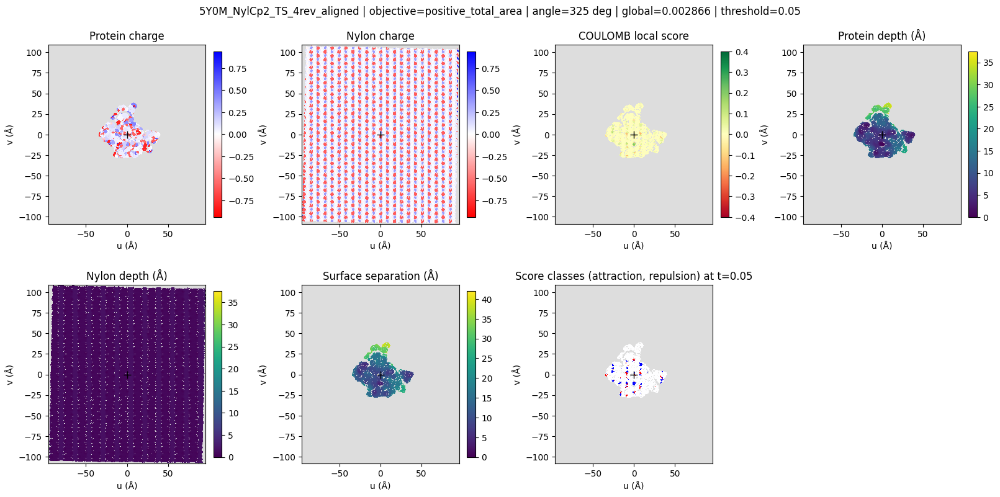

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/4EB0_LCC_4rev_aligned_positive_total_area_angle_220_thresh_0.05.png


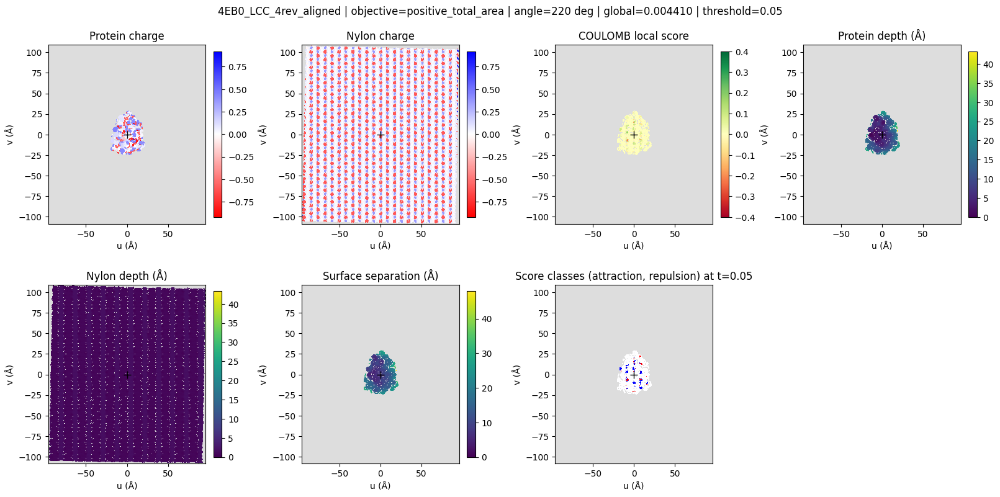

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/NfpolyA_AF3_4rev_aligned_positive_total_area_angle_329_thresh_0.05.png


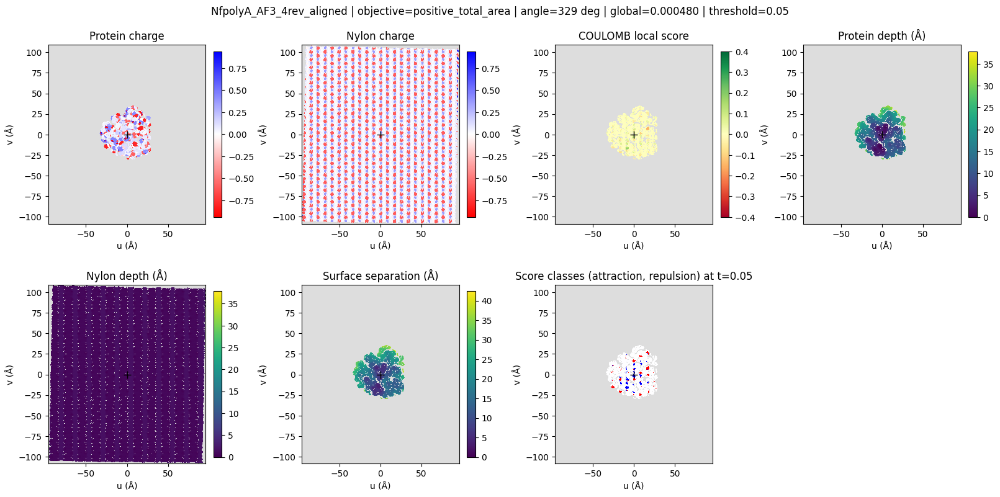

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/1SBC_Subtilisin_4rev_aligned_positive_total_area_angle_175_thresh_0.05.png


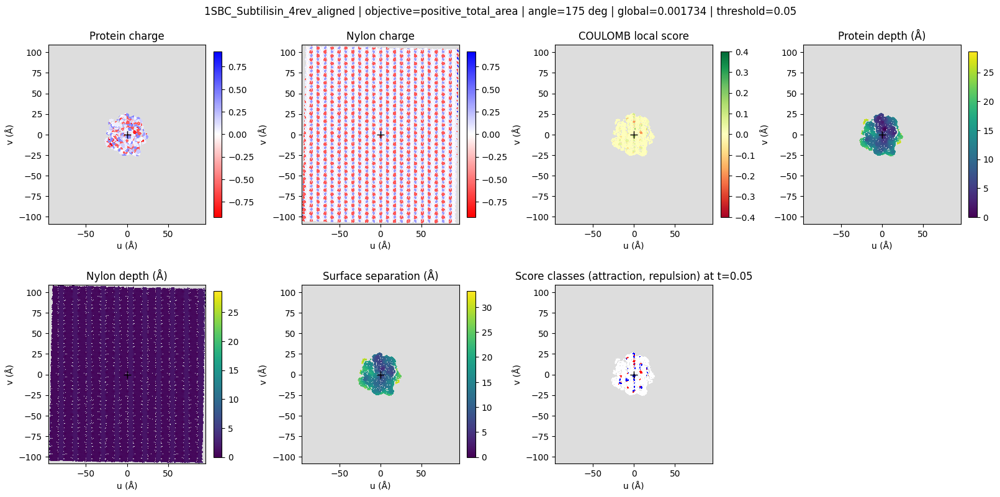

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/9FVF_UMGSP3_4rev_aligned_positive_total_area_angle_278_thresh_0.05.png


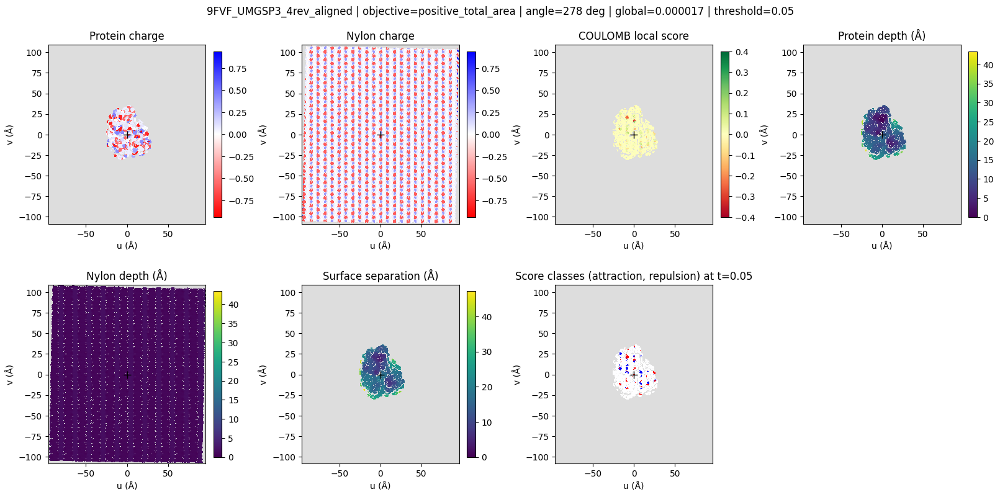

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/MsmegA_AF3_4rev_aligned_positive_total_area_angle_115_thresh_0.05.png


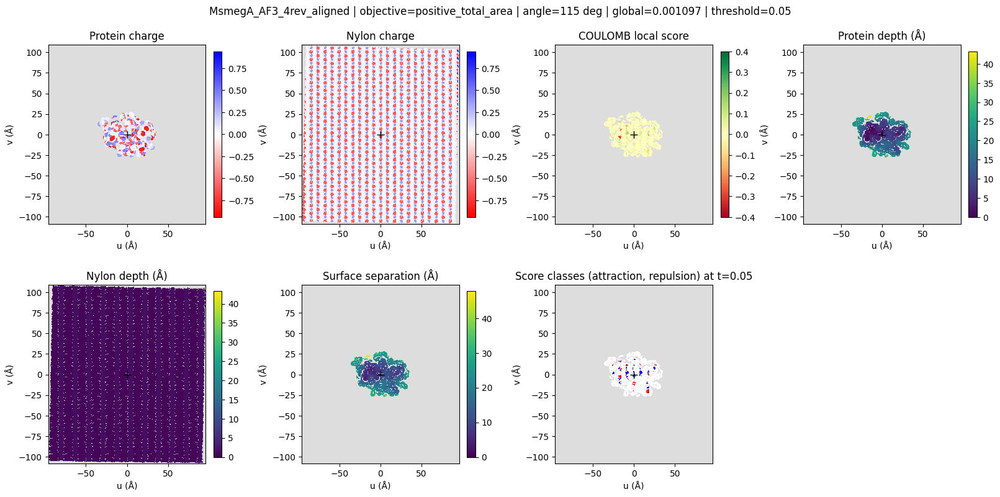

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/tt_NylC_AF3_4rev_aligned_positive_total_area_angle_254_thresh_0.05.png


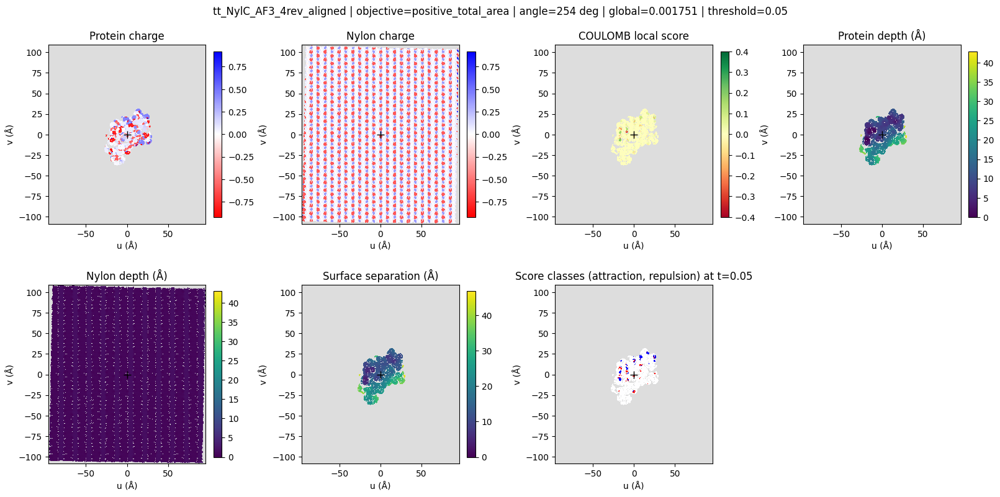

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/5LUJ_ThcCut2_4rev_aligned_positive_total_area_angle_130_thresh_0.05.png


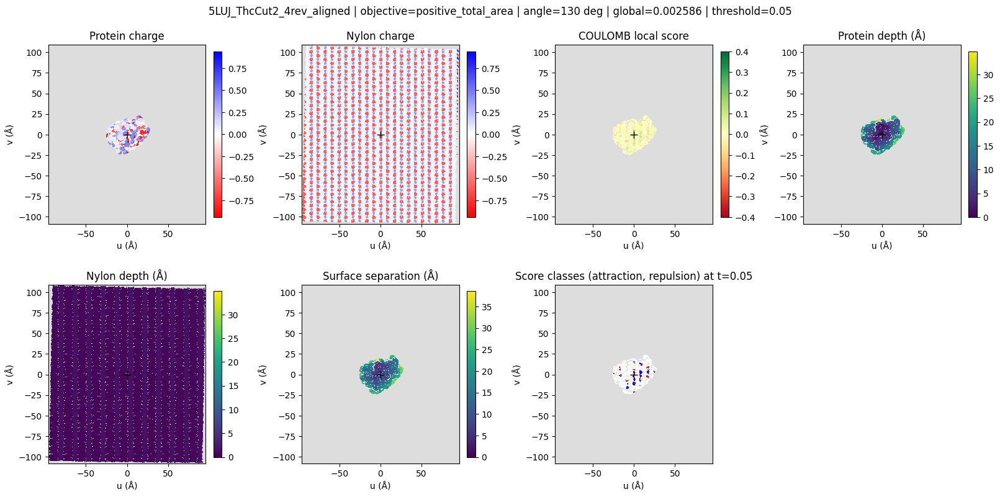

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/4CHA_chymotrypsin_4rev_aligned_positive_total_area_angle_123_thresh_0.05.png


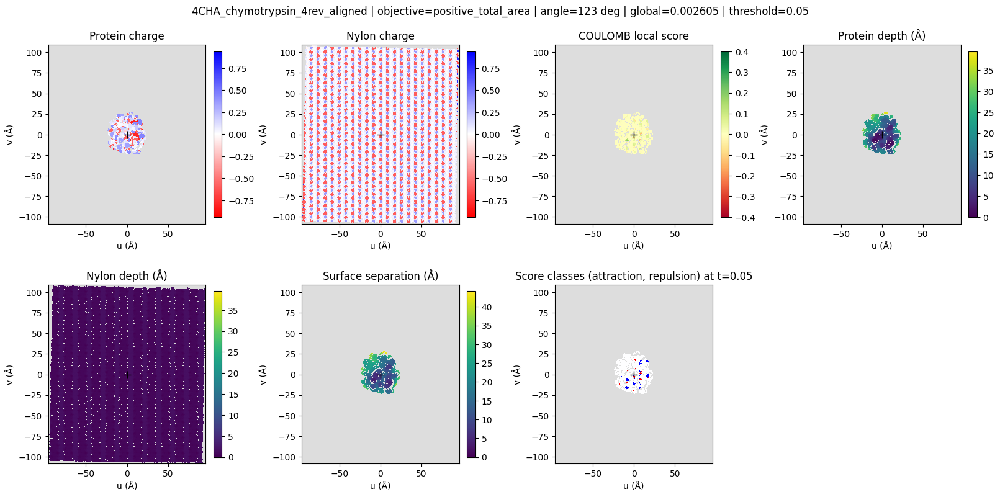

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/Rol10x_AF3_4rev_aligned_positive_total_area_angle_201_thresh_0.05.png


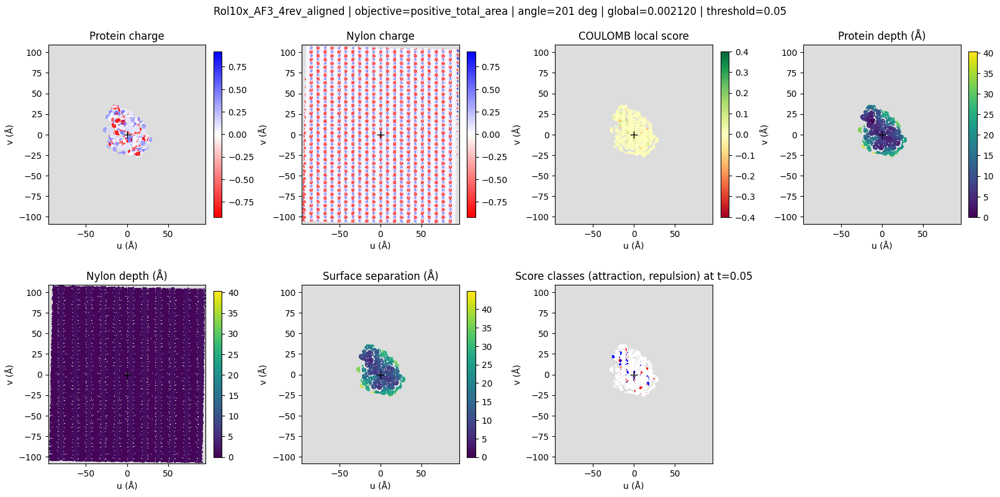

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/5LUI_ThcCut1_4rev_aligned_positive_total_area_angle_18_thresh_0.05.png


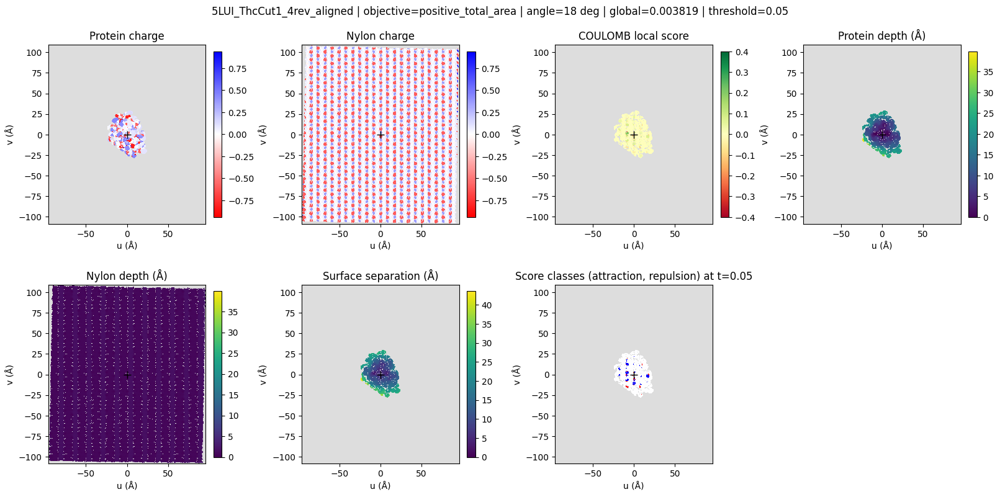

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/7QVH_HotPETase_4rev_aligned_positive_total_area_angle_182_thresh_0.05.png


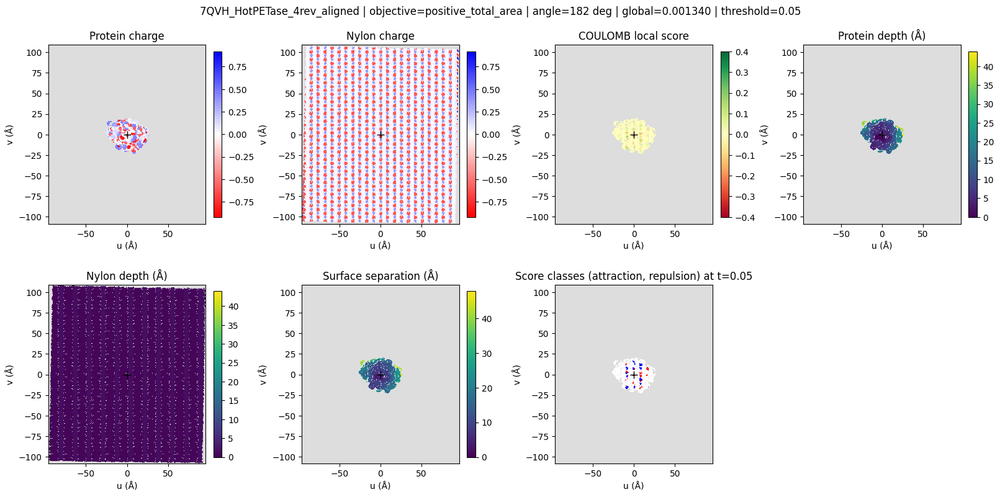

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/5XYG_NylCp2_4rev_aligned_positive_total_area_angle_85_thresh_0.05.png


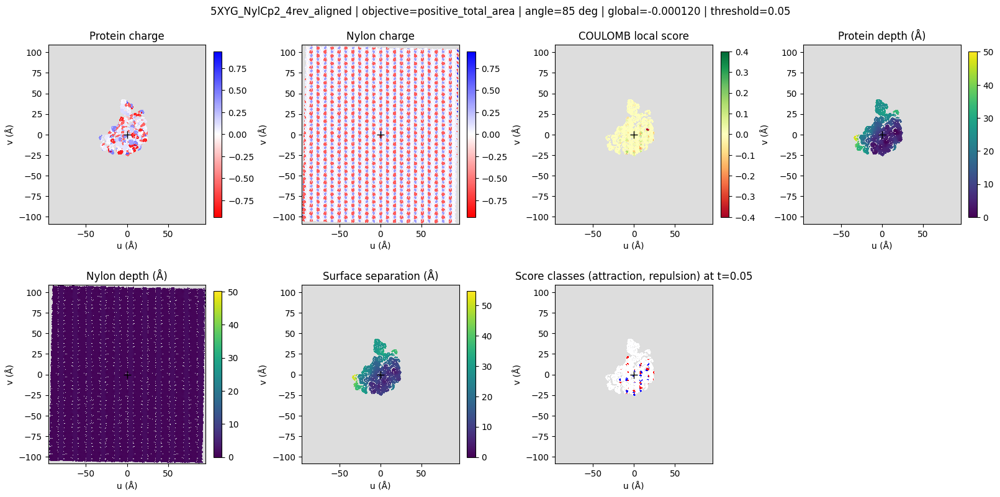

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/9DYS_Nyl50_4rev_aligned_positive_total_area_angle_254_thresh_0.05.png


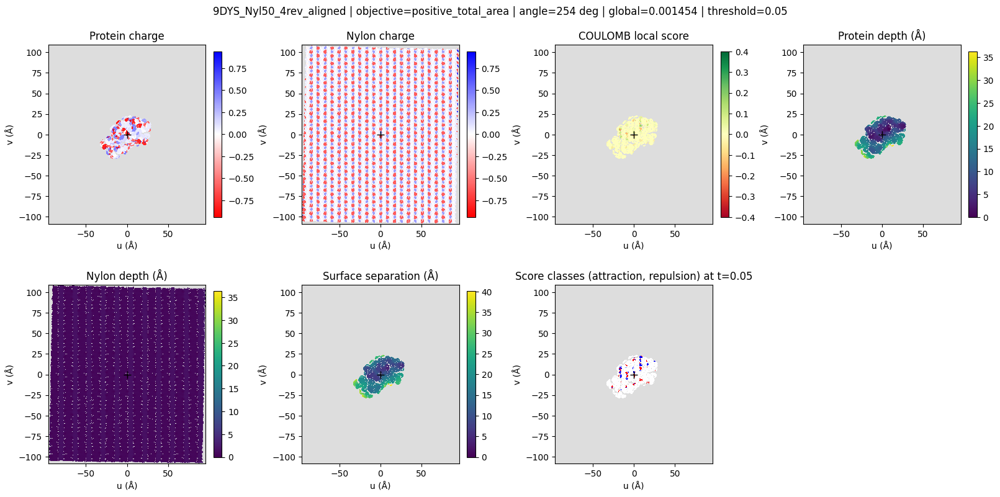

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/1DT5_lipTL_closed_4rev_aligned_positive_total_area_angle_318_thresh_0.05.png


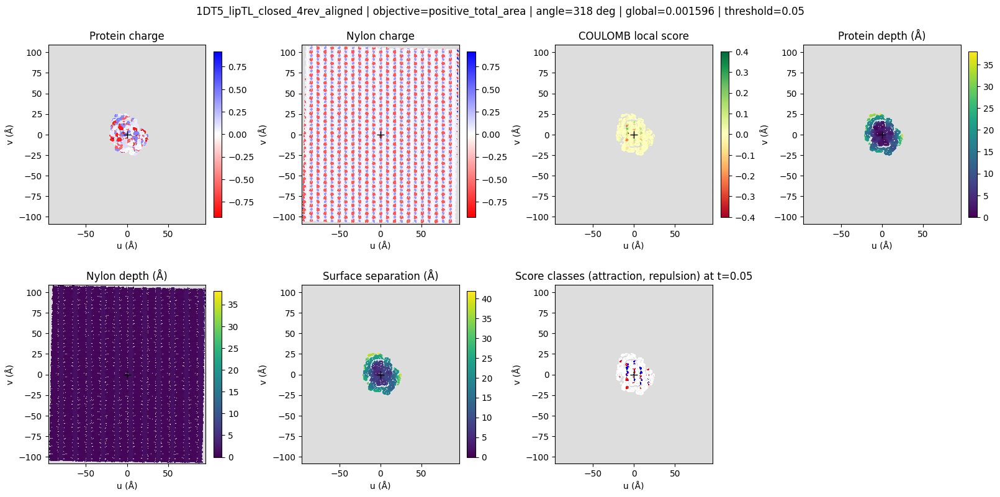

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/9FZW_UMGSP2_4rev_aligned_positive_total_area_angle_123_thresh_0.05.png


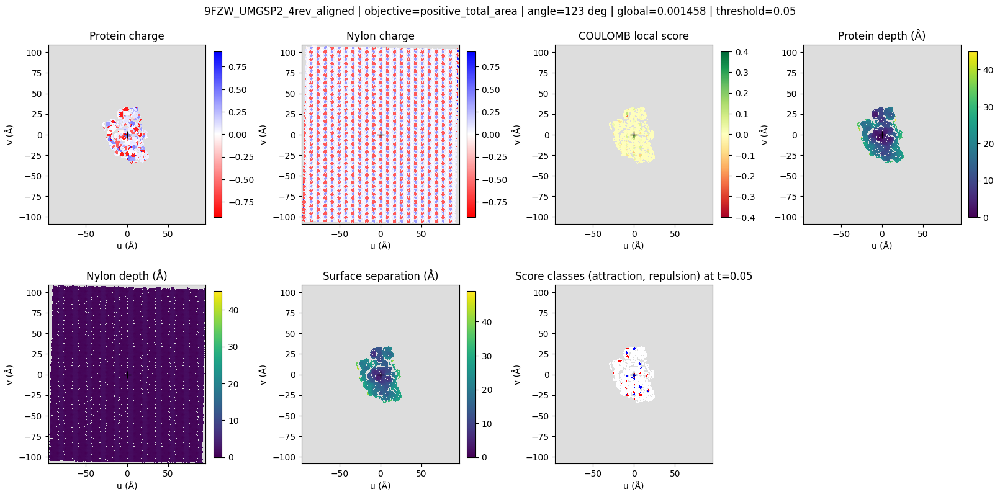

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/8WDW_UMGSP2_4rev_aligned_positive_total_area_angle_124_thresh_0.05.png


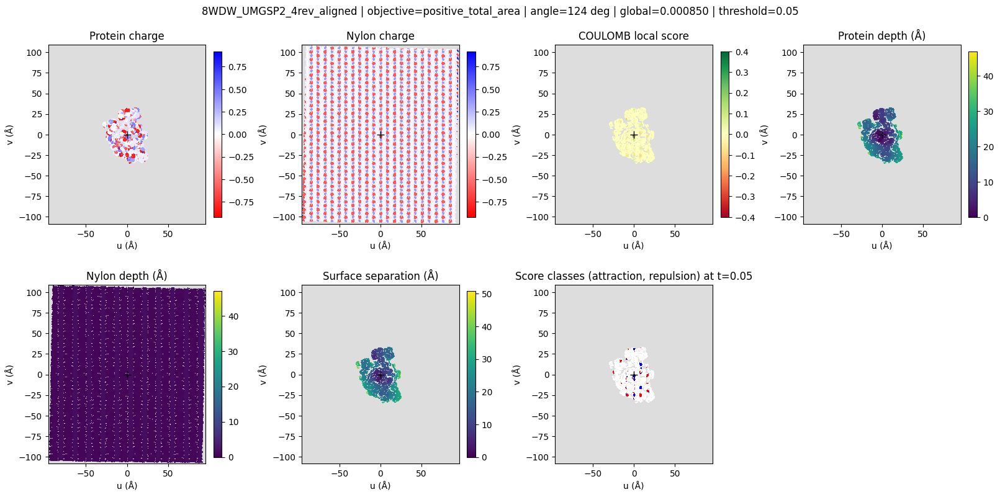

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/NylCk_AF3_4rev_aligned_positive_total_area_angle_28_thresh_0.05.png


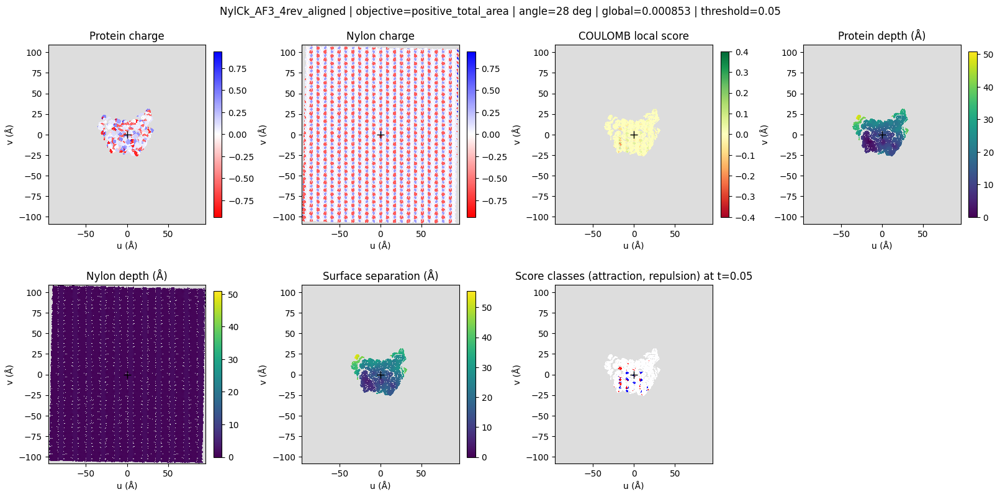

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/ReU_AF3_4rev_aligned_positive_total_area_angle_350_thresh_0.05.png


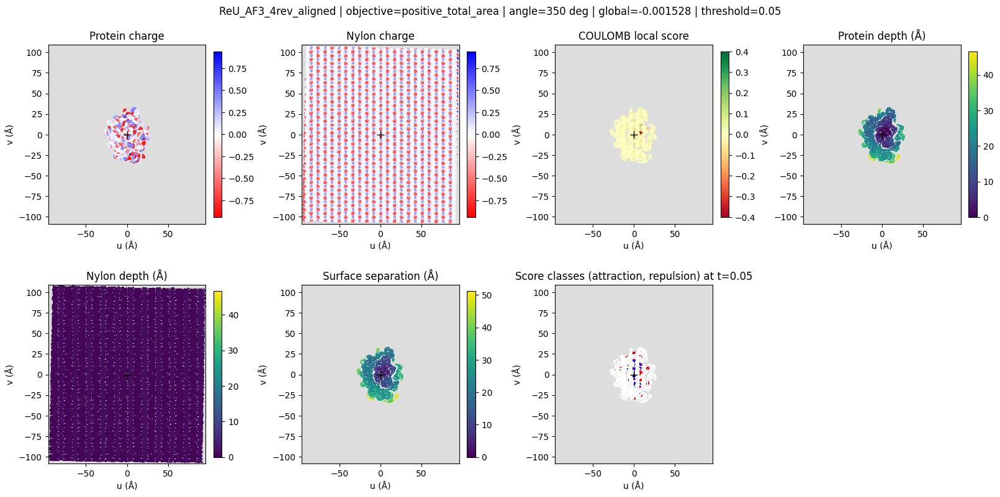

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/4CG1_Tfcut2_4rev_aligned_positive_total_area_angle_146_thresh_0.05.png


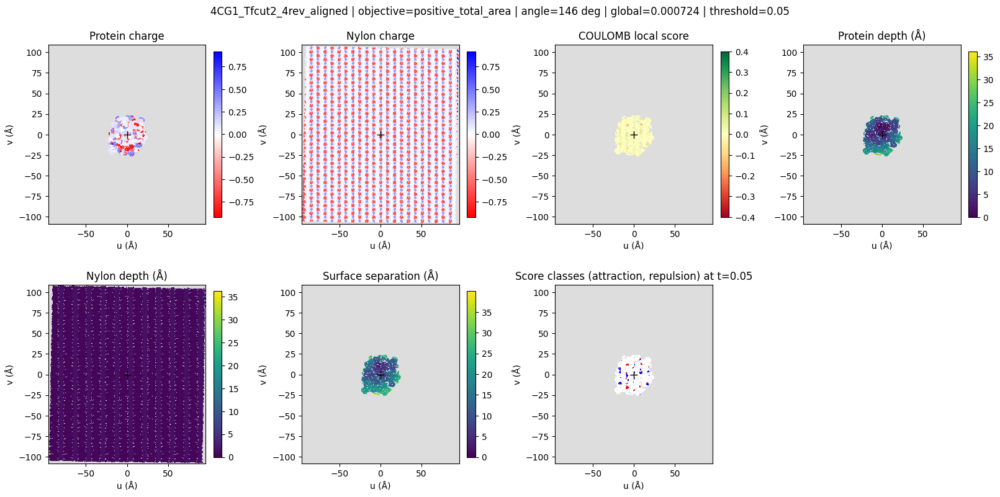

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/7CEF_Cut190_4rev_aligned_positive_total_area_angle_163_thresh_0.05.png


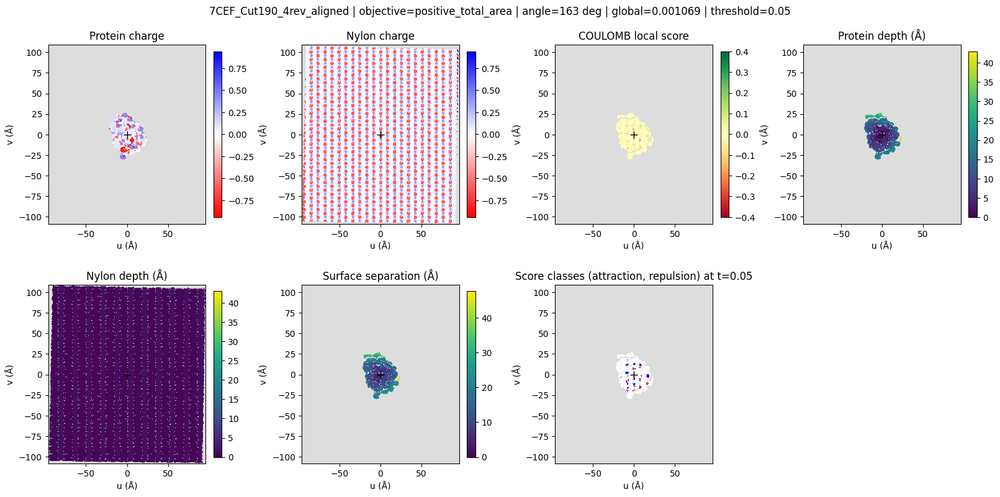

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/4TGL_lipRM_open_4rev_aligned_positive_total_area_angle_67_thresh_0.05.png


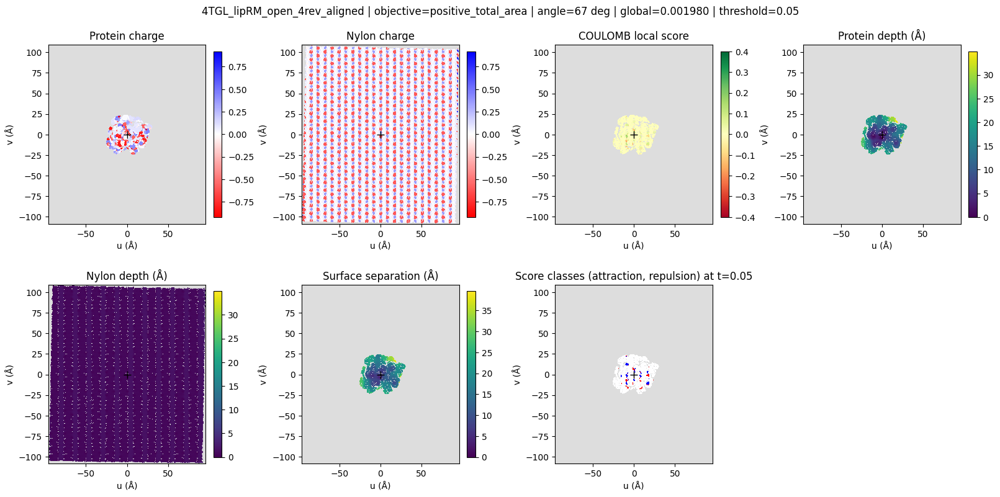

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/Ooh_AF3_4rev_aligned_positive_total_area_angle_278_thresh_0.05.png


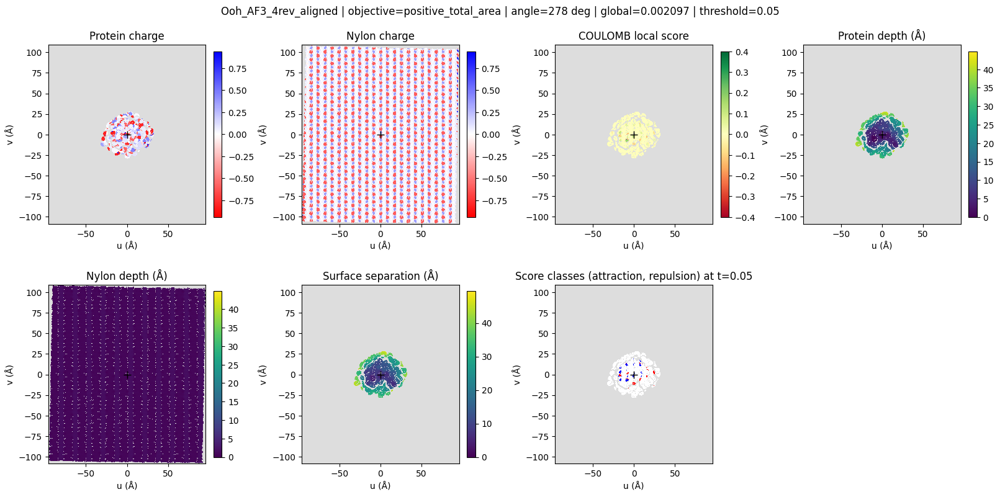

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/6YCE_Bromelain_CYS26_4rev_aligned_positive_total_area_angle_34_thresh_0.05.png


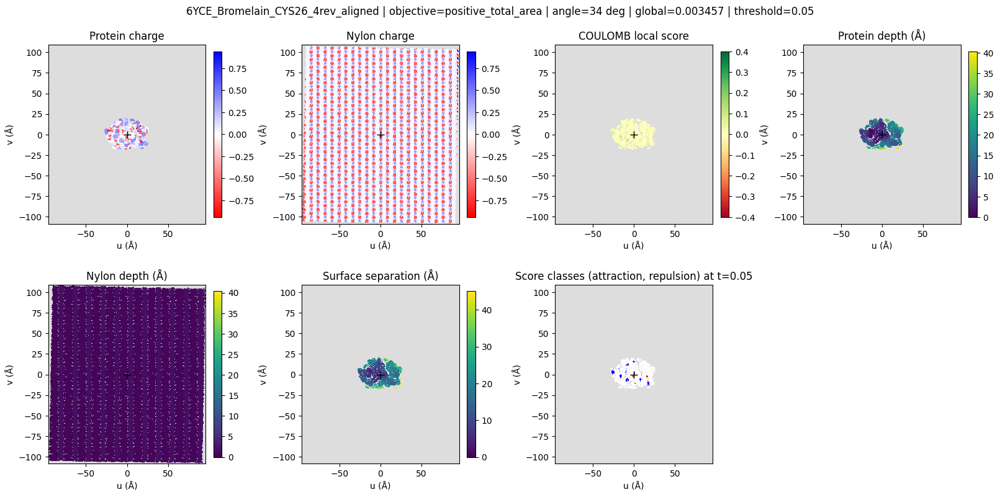

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/lipAN_AF3_4rev_aligned_positive_total_area_angle_326_thresh_0.05.png


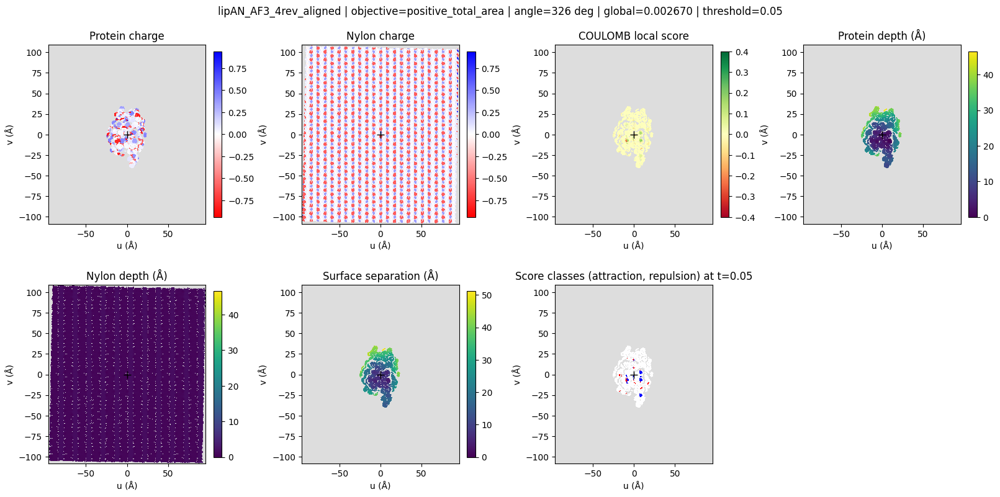

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/8OTA_LCC_ICCG_4rev_aligned_positive_total_area_angle_76_thresh_0.05.png


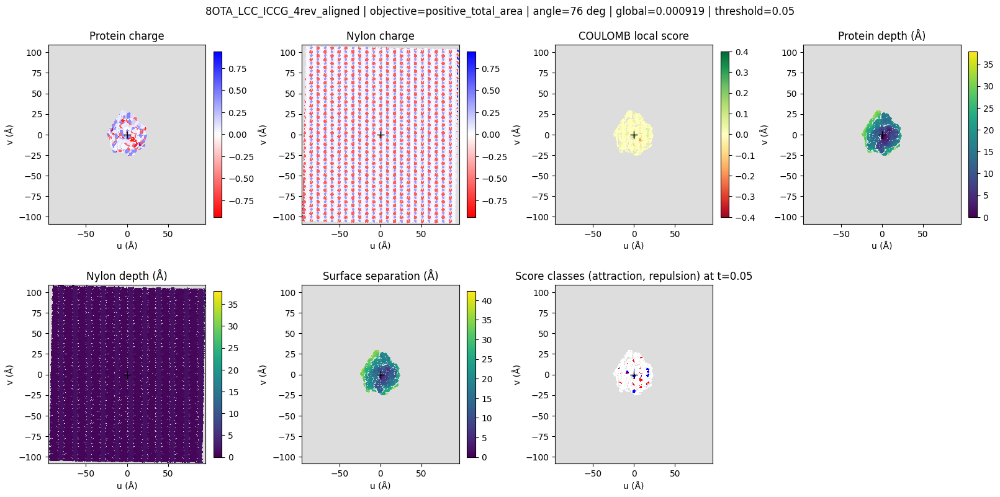

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/3TGL_LipRM_closed_4rev_aligned_positive_total_area_angle_357_thresh_0.05.png


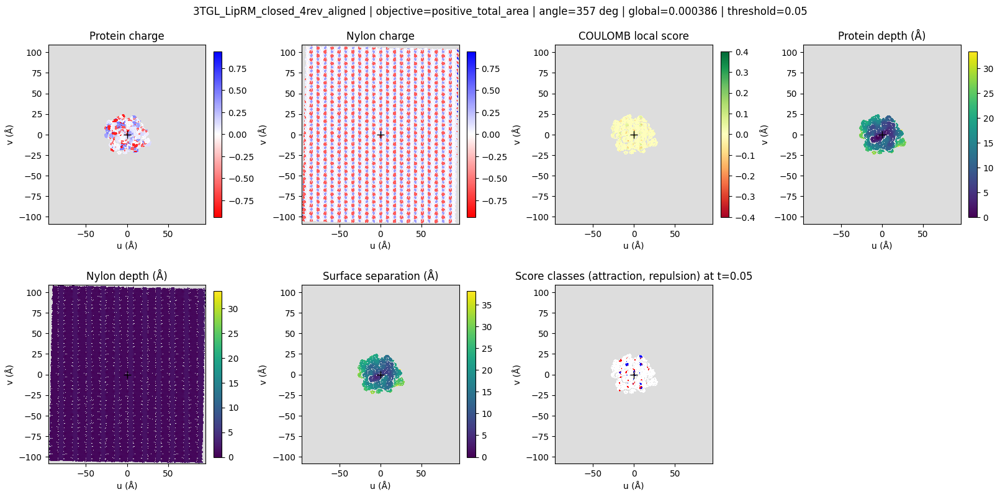

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/3AXG_NylCa_4rev_aligned_positive_total_area_angle_175_thresh_0.05.png


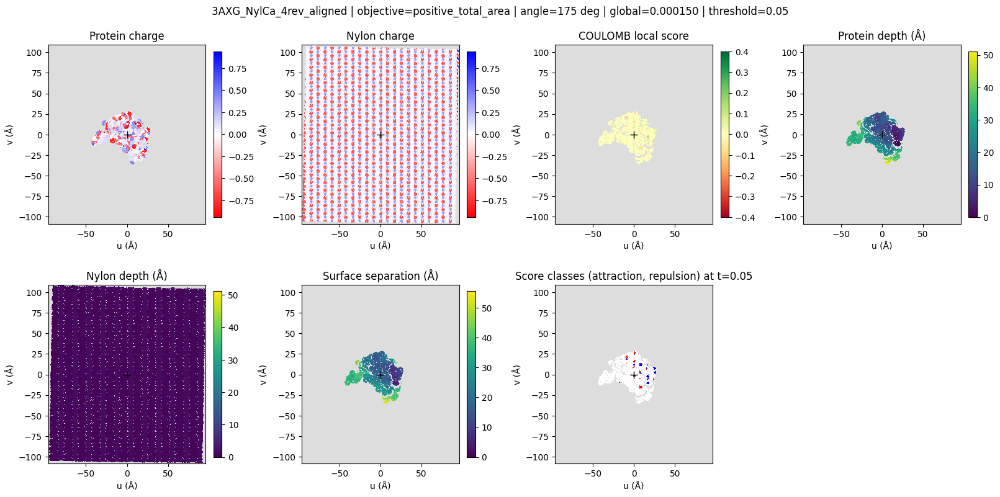

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/TtA_AF3_4rev_aligned_positive_total_area_angle_325_thresh_0.05.png


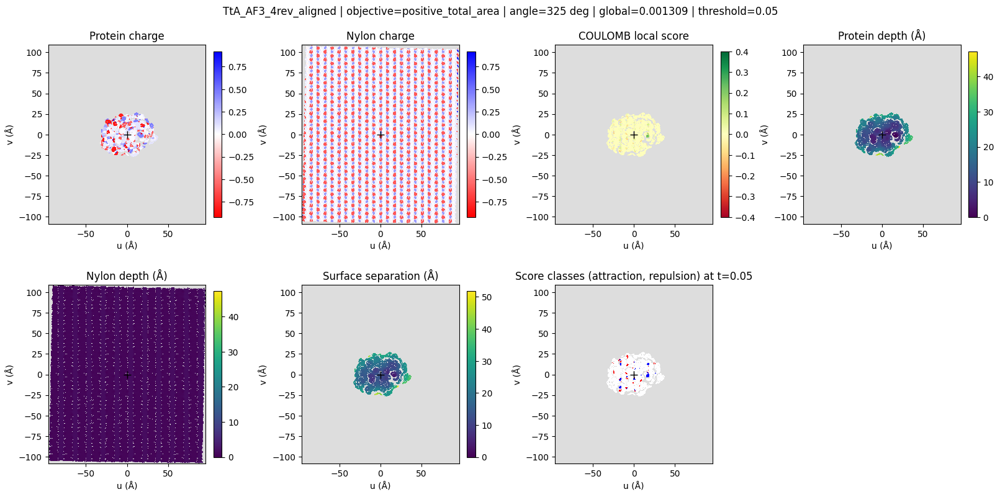

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/5D8M_MGS0156_4rev_aligned_positive_total_area_angle_76_thresh_0.05.png


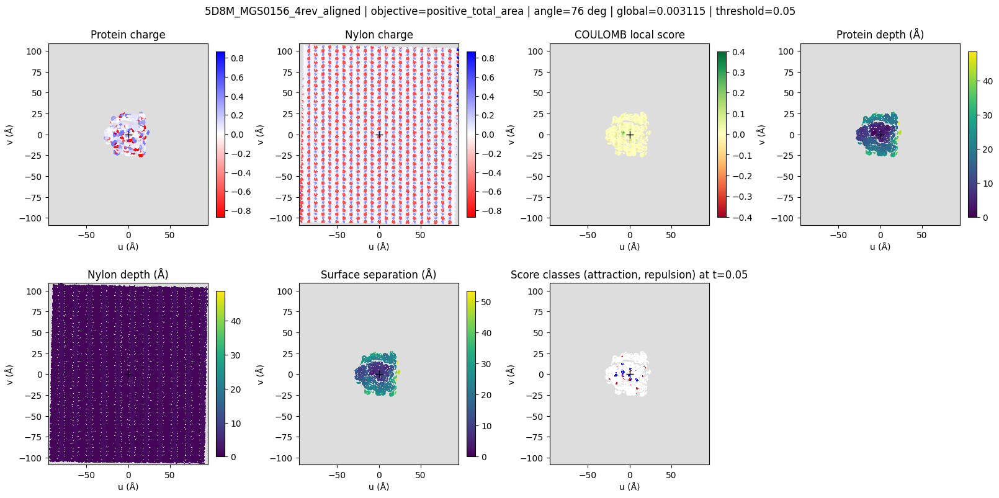

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/8S7Z_UMGSP1_4rev_aligned_positive_total_area_angle_130_thresh_0.05.png


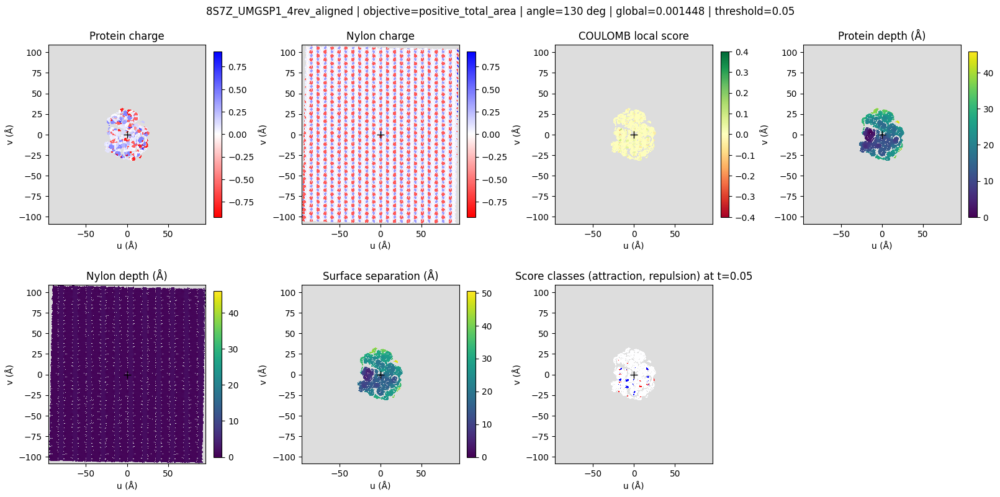

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/1TRH_lipCR_closed_4rev_aligned_positive_total_area_angle_151_thresh_0.05.png


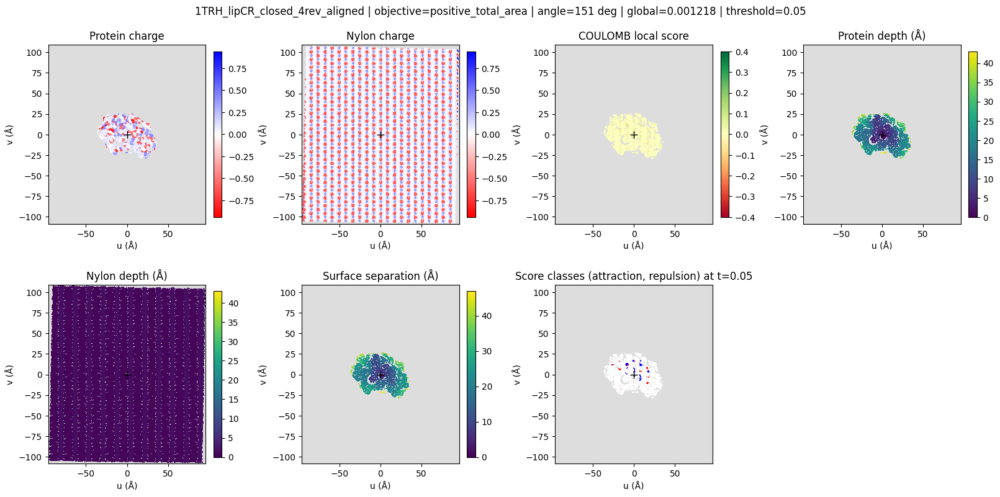

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/nc_NylC_AF3_4rev_aligned_positive_total_area_angle_89_thresh_0.05.png


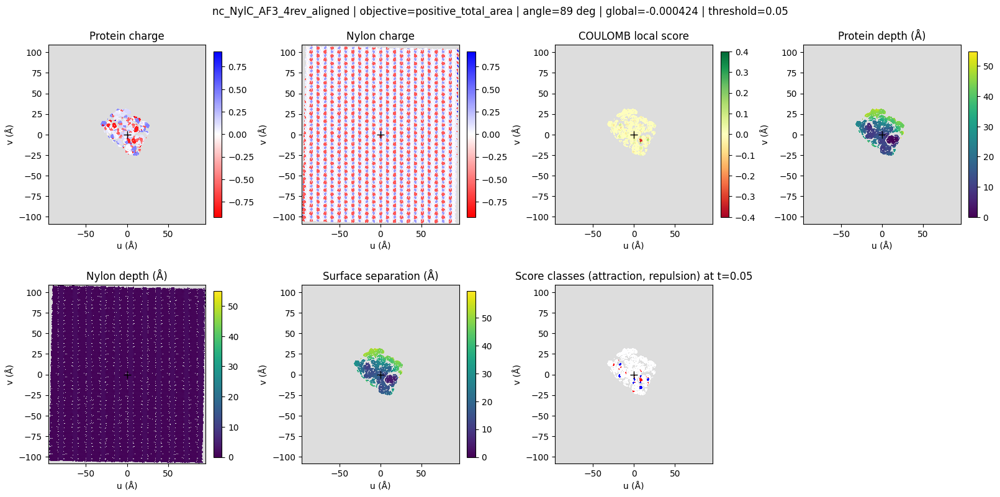

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/BcC_AF3_4rev_aligned_positive_total_area_angle_5_thresh_0.05.png


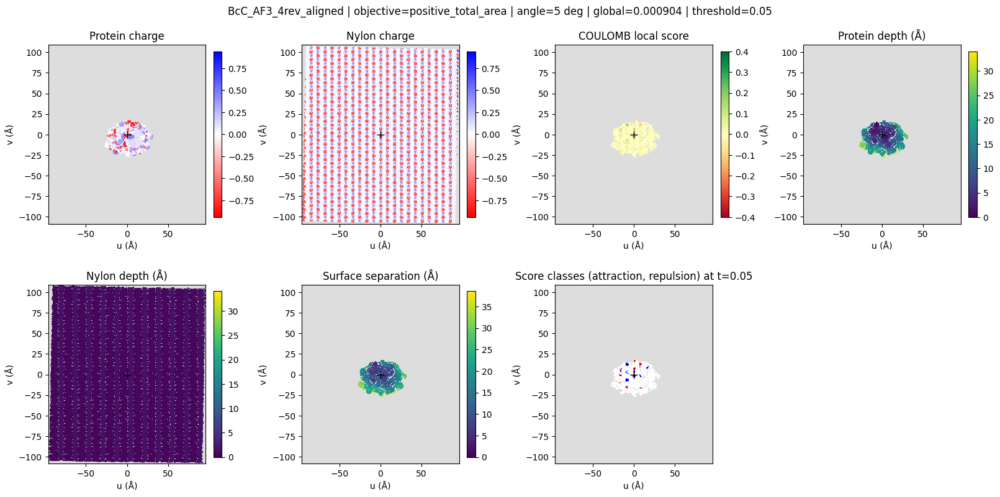

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/1TPO_Trypsin_4rev_aligned_positive_total_area_angle_241_thresh_0.05.png


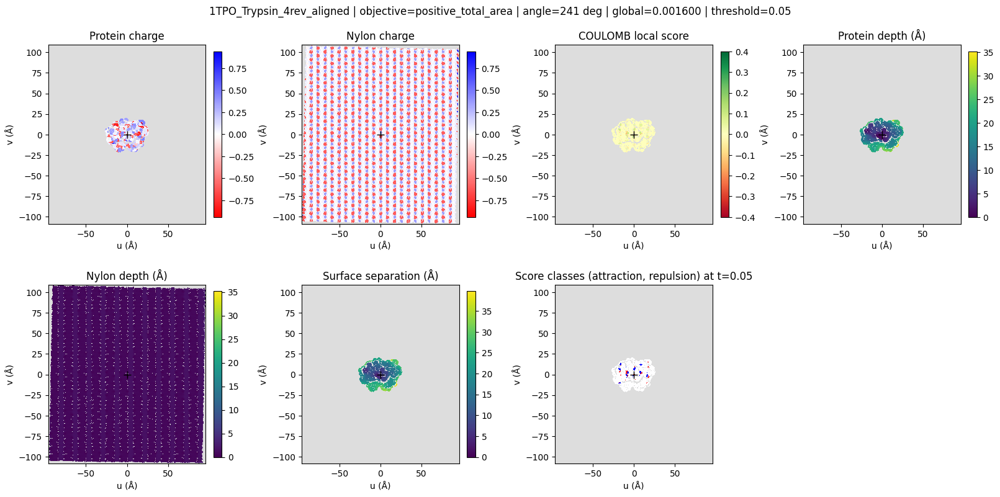

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/1CUS_fsc_4rev_aligned_positive_total_area_angle_271_thresh_0.05.png


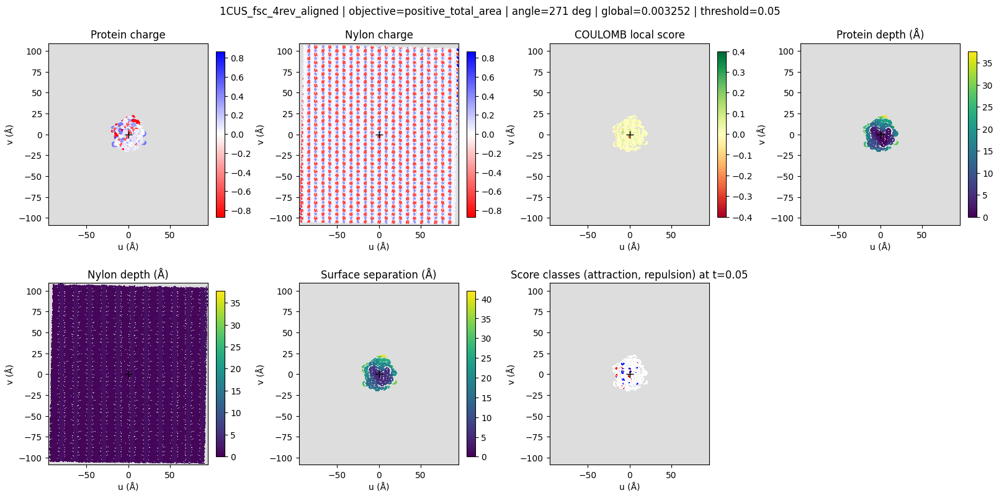

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/1PPN_Papain_4rev_aligned_positive_total_area_angle_61_thresh_0.05.png


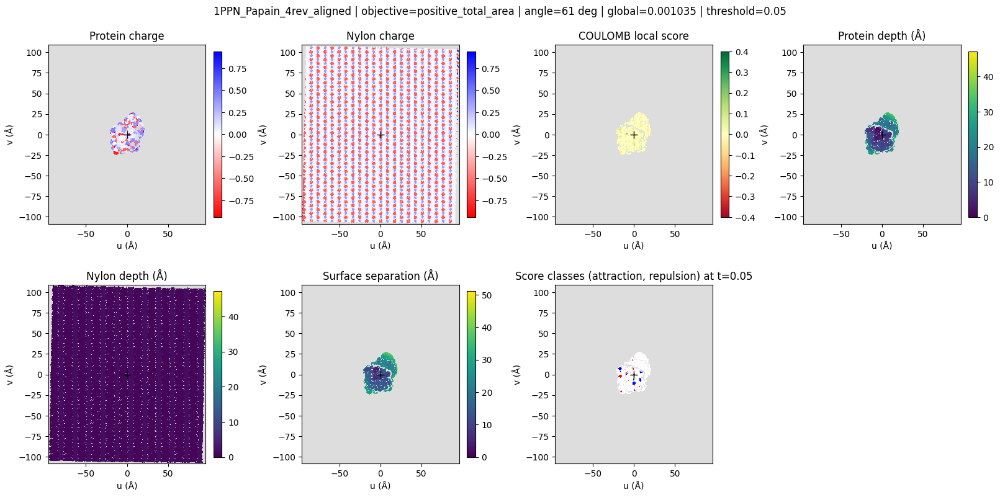

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/afnitB_AF3_4rev_aligned_positive_total_area_angle_265_thresh_0.05.png


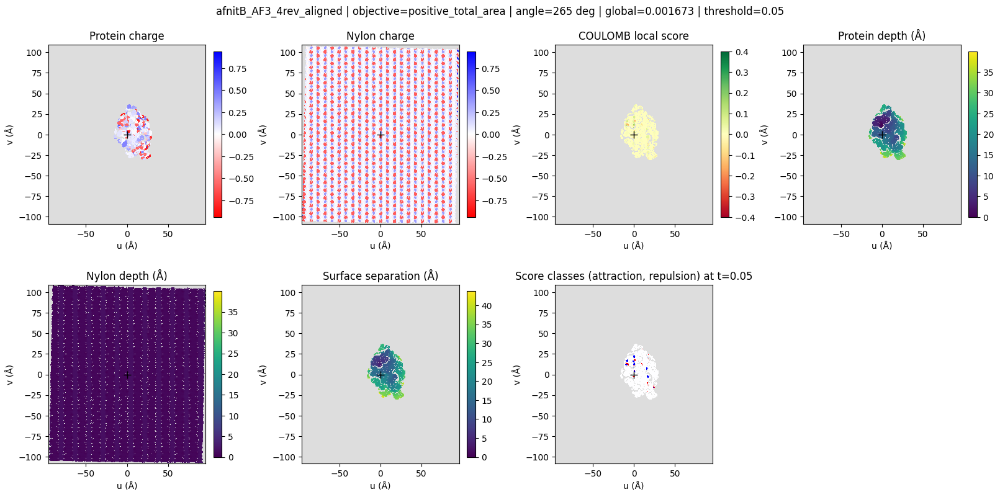

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/GatA_AF3_4rev_aligned_positive_total_area_angle_196_thresh_0.05.png


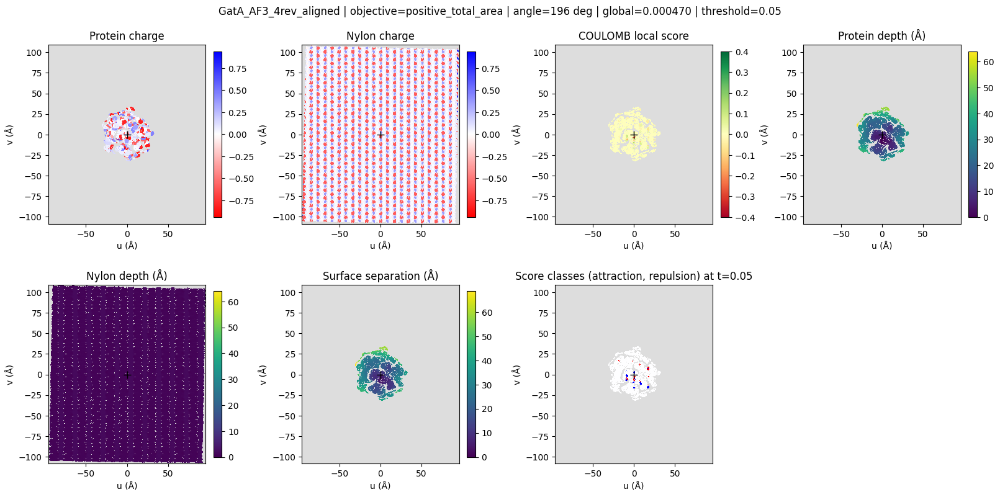

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/4OYY_HiC_4rev_aligned_positive_total_area_angle_16_thresh_0.05.png


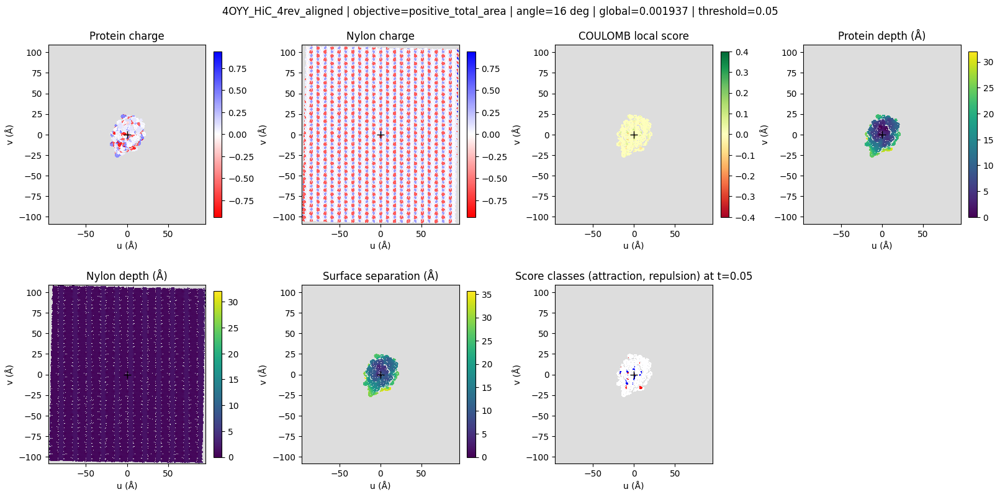

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/TvgC_AF3_4rev_aligned_positive_total_area_angle_49_thresh_0.05.png


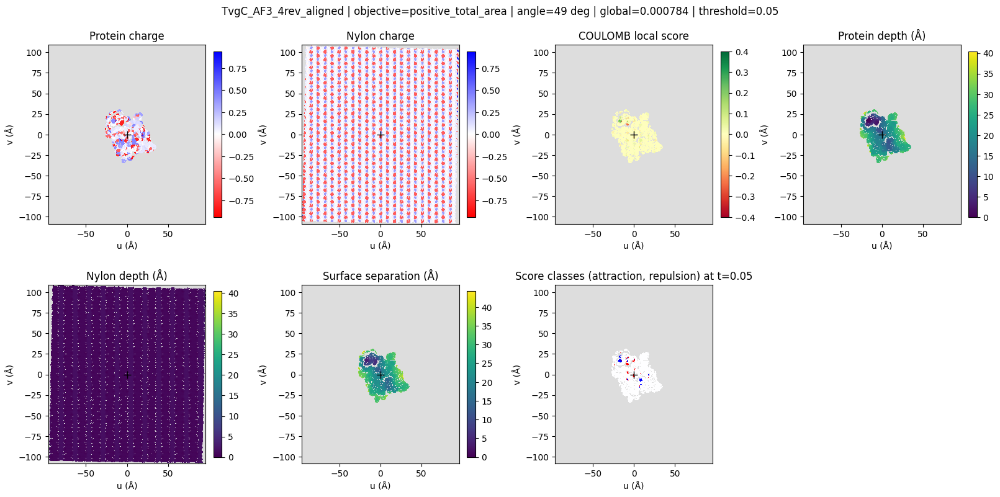

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/1WYB_NylB_4rev_aligned_positive_total_area_angle_306_thresh_0.05.png


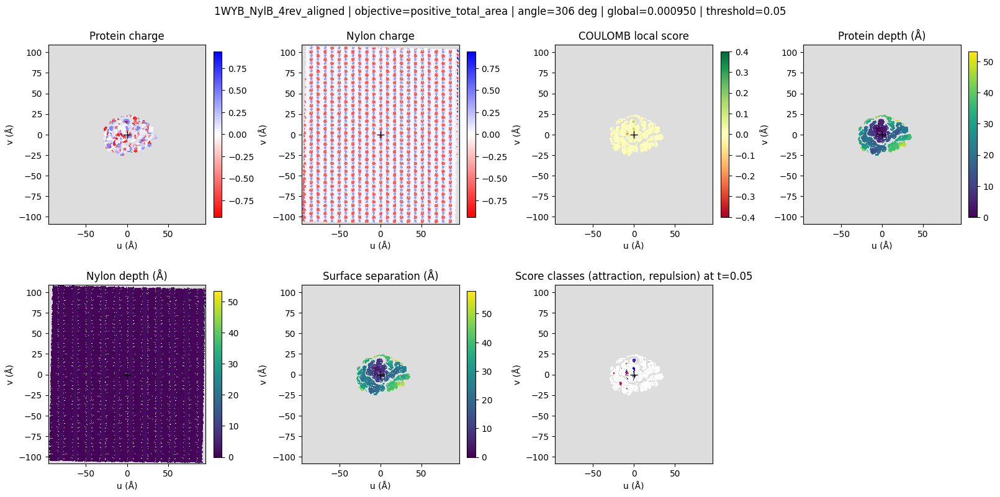

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/pam1_AF3_4rev_aligned_positive_total_area_angle_72_thresh_0.05.png


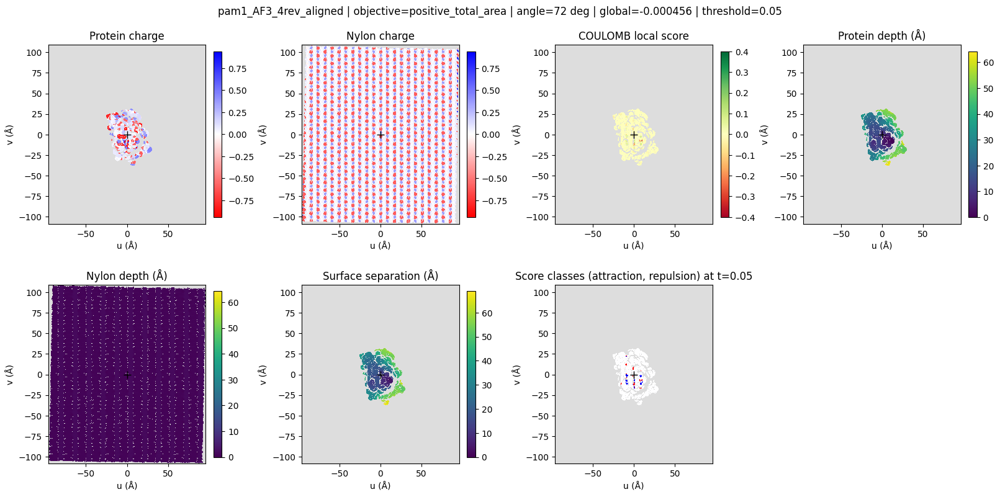

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/1FFA_FsC_N84A_4rev_aligned_positive_total_area_angle_271_thresh_0.05.png


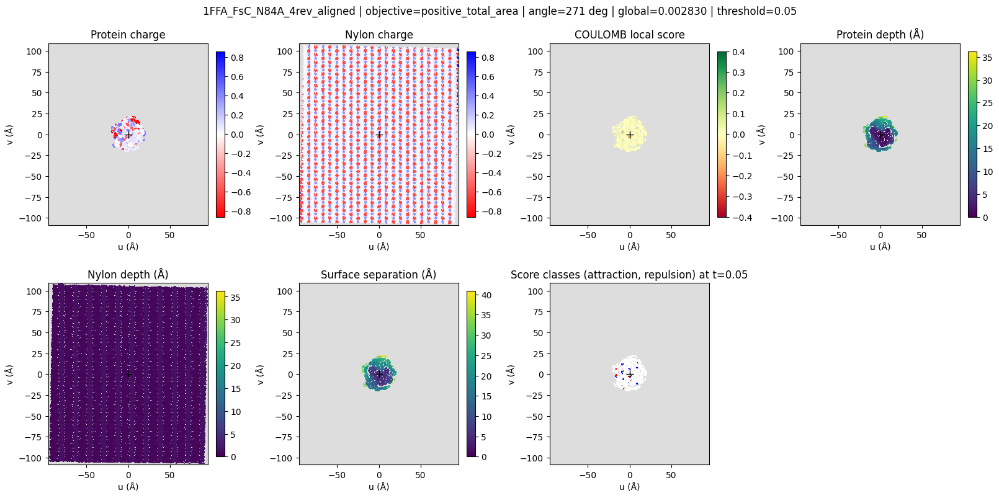

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/ph_NylC_AF3_4rev_aligned_positive_total_area_angle_12_thresh_0.05.png


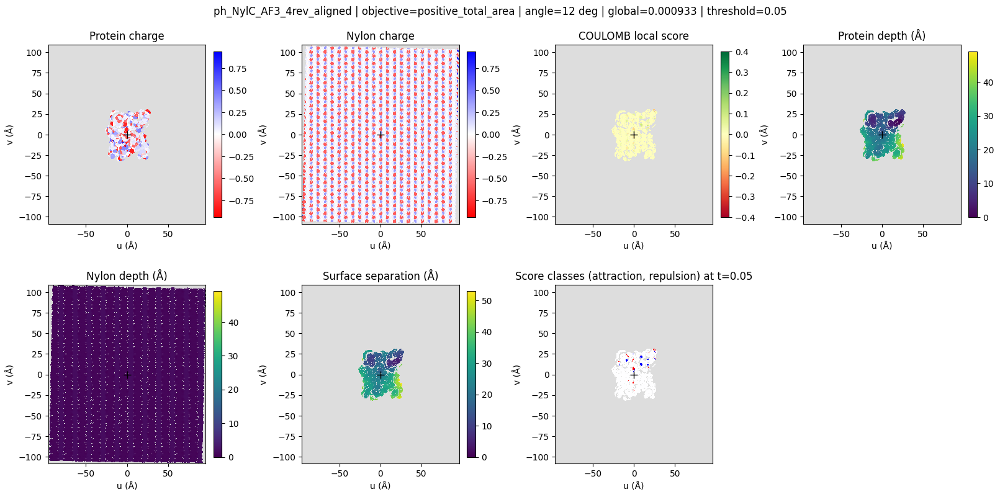

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/1DTE_lipTL_open_4rev_aligned_positive_total_area_angle_86_thresh_0.05.png


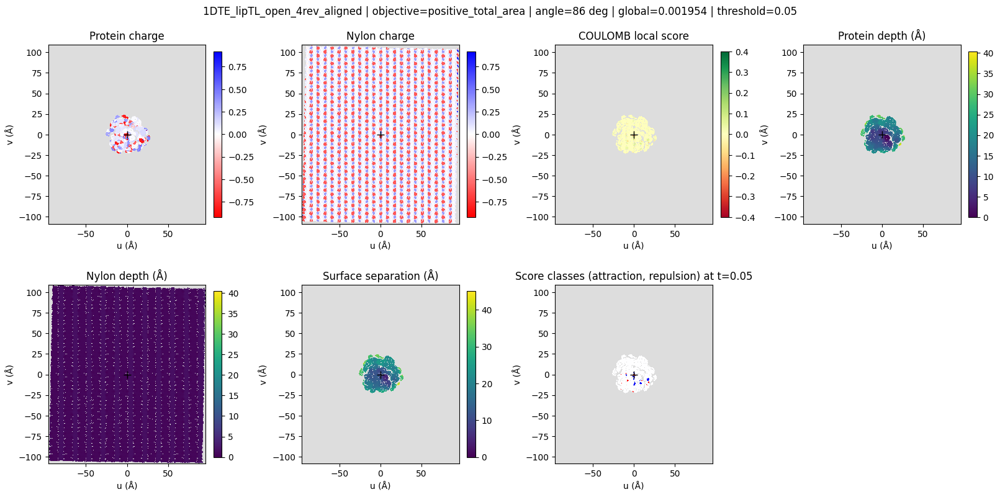

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/3GBS_AoC_4rev_aligned_positive_total_area_angle_261_thresh_0.05.png


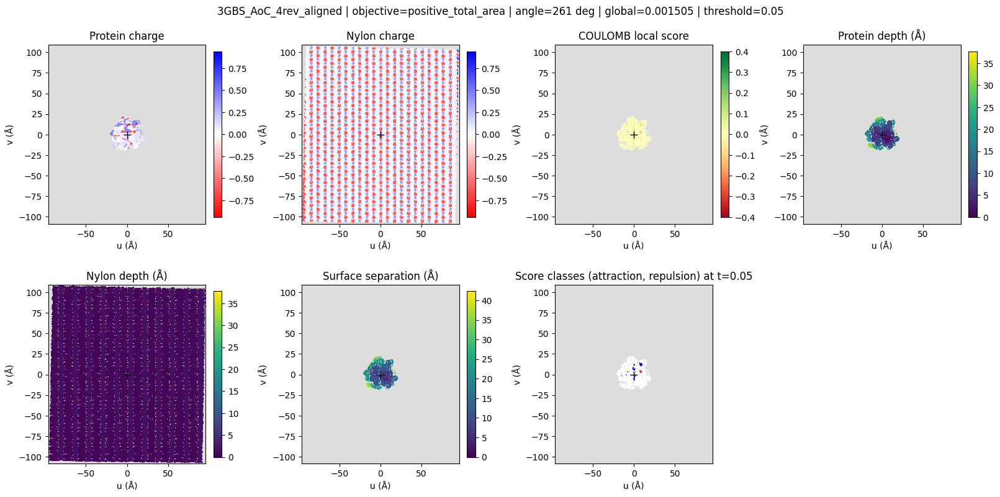

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/1CEX_FsC_4rev_aligned_positive_total_area_angle_62_thresh_0.05.png


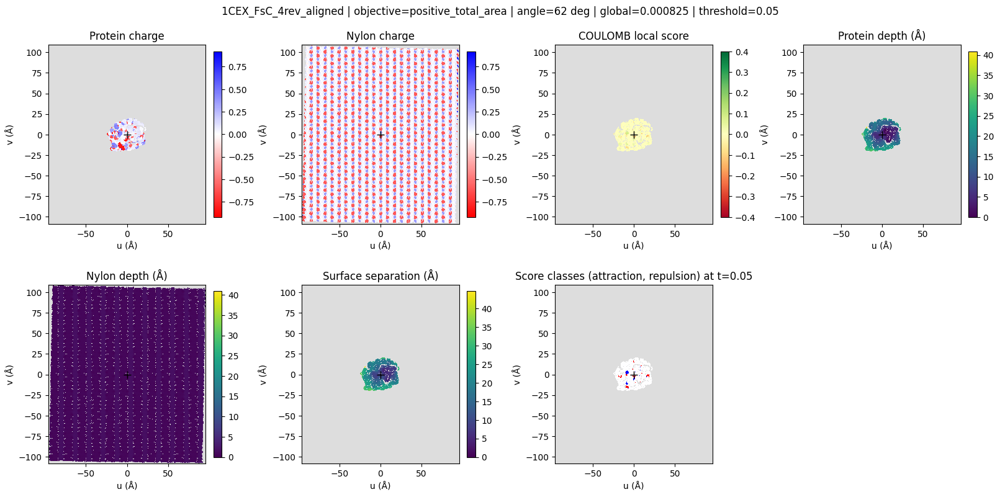

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/1CRL_lipCr_open_4rev_aligned_positive_total_area_angle_283_thresh_0.05.png


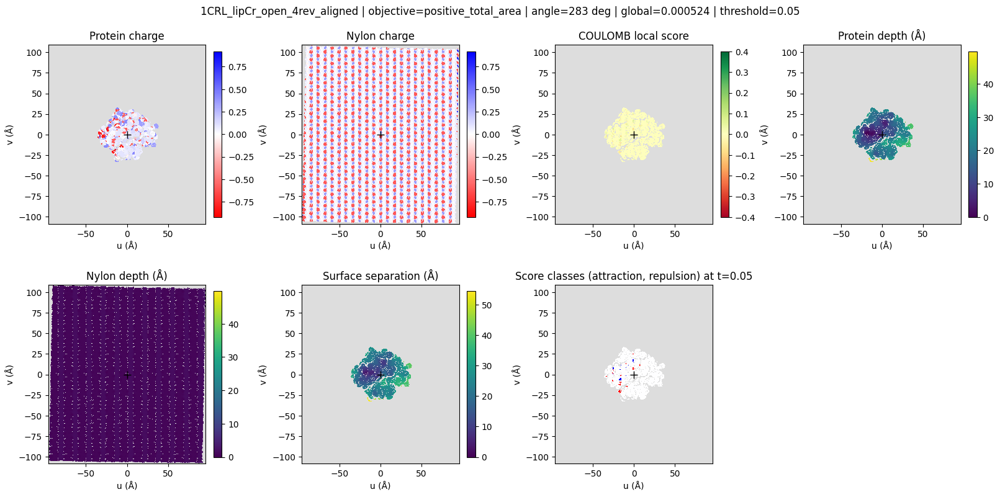

Zapisano wykres: /content/drive/MyDrive/phD_interview/SOLENZ/dataToPCAplots/planar_matching_coulomb_fixed_new_dataset_14_10/coulomb_gap3_ref3_pixel0.25A_areaA2/figures/1OIL_LipBC_open_4rev_aligned_positive_total_area_angle_57_thresh_0.05.png


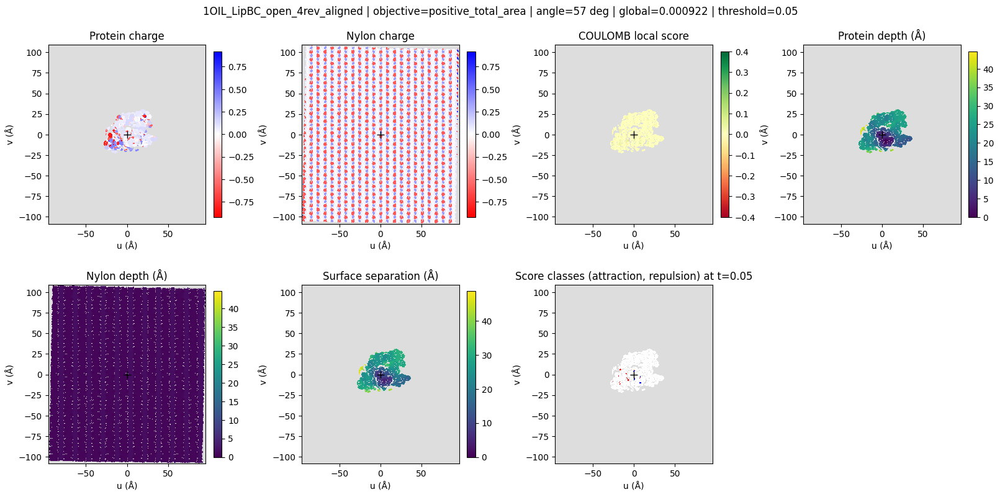

In [ ]:
def selected_table(rankings, objective, threshold):
    table = rankings[(rankings.objective == objective) &
                     np.isclose(rankings.threshold, threshold, rtol=0, atol=1e-12)]
    if table.empty:
        raise ValueError(f'No exported table for {objective} at {threshold:g}. '
                         f'Available thresholds: {sorted(rankings.threshold.unique())}')
    return table


def show_pose(protein, nylon, row, config):
    axis, (U, V) = canvas_for_pair(protein, nylon, config)
    qn, dn, mn = sample_surface(nylon, U, V, interpolation=config.interpolation)
    qp, dp, mp = sample_surface(protein, U, V, row.angle, config.mirror,
                                 interpolation=config.interpolation)
    paired = mp & mn
    distance_map = surface_separation(dp, dn, paired, config.gap_A)
    local, distance = coulomb_map(qp, qn, distance_map, paired, config)
    rmap = np.full(paired.shape, np.nan)
    rmap[paired] = distance
    classes = np.full(paired.shape, np.nan)
    classes[paired] = 0
    classes[local > row.threshold] = 1
    classes[local < -row.threshold] = -1

    h = config.pixel_size_A
    extent = (axis[0] - h/2, axis[-1] + h/2, axis[0] - h/2, axis[-1] + h/2)

    charge_limit = max(float(np.abs(qp[mp]).max()), float(np.abs(qn[mn]).max()), 1e-12)
    depth_limit = max(float(dp[mp].max()), float(dn[mn].max()), 1e-12)
    local_limit = max(float(np.abs(local[paired]).max()), 1e-12)

    panels = [(qp, 'Protein charge', 'bwr_r', -charge_limit, charge_limit),
              (qn, 'Nylon charge', 'bwr_r', -charge_limit, charge_limit),
              (local, 'COULOMB local score', 'RdYlGn', -0.4, 0.4),
              (dp, 'Protein depth (Å)', 'viridis', 0, depth_limit),
              (dn, 'Nylon depth (Å)', 'viridis', 0, depth_limit),
              (rmap, 'Surface separation (Å)', 'viridis', 0, float(distance.max())),
              (classes, f'Score classes (attraction, repulsion) at t={row.threshold:g}', 'bwr_r', -1, 1)]

    fig, axes = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
    r, c = np.nonzero(mp | mn)
    crop = (axis[max(0, c.min()-2)], axis[min(len(axis)-1, c.max()+2)],
            axis[max(0, r.min()-2)], axis[min(len(axis)-1, r.max()+2)])

    for ax, (data, title, palette, lo, hi) in zip(axes.ravel(), panels):
        cmap = plt.get_cmap(palette).copy()
        cmap.set_bad('#dddddd')
        image = ax.imshow(np.ma.masked_invalid(data), origin='lower', extent=extent,
                          cmap=cmap, vmin=lo, vmax=hi, interpolation='nearest')
        ax.plot(0, 0, 'k+', ms=8)
        ax.set(title=title, xlabel='u (Å)', ylabel='v (Å)',
               xlim=crop[:2], ylim=crop[2:])

        if data is not classes:
            colourbar = fig.colorbar(image, ax=ax, shrink=0.75)

    axes.ravel()[-1].axis('off')
    fig.suptitle(f'{protein.name} | objective={row.objective} | angle={row.angle:g} deg | '
                 f'global={row.global_score:.6f} | threshold={row.threshold:g}')

    output_dir = Path(OUTPUT_DIR) / 'figures'
    output_dir.mkdir(parents=True, exist_ok=True)

    filename = f"{protein.name}_{row.objective}_angle_{row.angle:g}_thresh_{row.threshold:g}.png"
    filename = filename.replace('/', '_').replace('\\', '_')
    filepath = output_dir / filename

    fig.savefig(filepath, dpi=300, bbox_inches='tight')
    print(f"Zapisano wykres: {filepath}")

    plt.show()
    plt.close(fig)




if DISPLAY_OBJECTIVE not in OBJECTIVES:
    raise ValueError(f'DISPLAY_OBJECTIVE must be one of {OBJECTIVES}.')
if run_summary['no_patches_at_start']:
    DISPLAY_OBJECTIVE = 'global_score'
    DISPLAY_THRESHOLD = CONFIG.threshold_start
selected = selected_table(rankings, DISPLAY_OBJECTIVE, DISPLAY_THRESHOLD)
display(selected[EXPORT_COLUMNS])
if SHOW_TOP_MAPS:
    for _, row in selected.head(TOP_N_MAPS).iterrows():
        show_pose(load_surface(PROTEIN_PATHS[row.protein], row.protein), nylon, row, CONFIG)
